# Benchmark Results

This notebook reproduces the benchmark figures of the paper on the main survival scenario
`survival-second-price-exponential` for two mean campaign lengths, **η = 50** (the main setting) and **η = 100**:
campaign length $T \sim \mathrm{Exp}$ (mean η), Poisson(1) auction opportunities, second-price auctions, competing bid
LogNormal(−1, 1), multiplicative fatigue (c = 0.9, β = 1). For each η, every policy is evaluated on the same **1 000 test
campaigns** (environment seeds 0–999; randomised policies use seed + 1000), so differences between policies are paired.

Policies:
- planning: **MPC**(H = 10, 25, 35; M = 60 rollouts), **MPC**(H = 25; M = 80), **MPC**(H = 25, 35; M = 60;
  α_cont = 0.4), **Shading**(best α of the sweep below, M = 40; α = 0.4 at η = 50) and **GreedyMyopic** (Shading with
  α = 1, M = 20);
- references: **FiPla** (bids the oracle value $V_0$ of the display) and **Constant** (best bid of the sweep below);
- RL: **PPO**, **TD3** and **SAC**, each retrained 3 times (training seeds 42, 43, 44) with the hyperparameters selected on
  200 validation campaigns (seeds 20000–20199). Tables and aggregate plots use the mean of the 3 trainings per campaign;
  per-step plots pool the 3 trainings.

η = 100 follows the same protocol, with the MLP valuation head of MPC retrained at η = 100 (same procedure), the RL
hyperparameters selected at η = 50 (no new search) retrained and tested at η = 100, the best α and the best b of the η = 100
sweeps, and α_cont = 0.4 as at η = 50. Every section shows η = 50, then η = 100; the η = 100 runs that are not finished
yet are listed when the results are loaded.

## Data

The notebook reads `benchmark/benchmark_results/main/` (η ∈ {50, 100}):
- `survival-second-price-exponential_eta<η>_results_final.csv.gz`: per-step logs of every policy (policy, seed, step, t,
  reward, cum_reward, won, bid, payment, ctx, expected_reward, competing_bid, alpha_chosen); the RL trainings are labelled
  `PPO (training k)`, `TD3 (training k)`, `SAC (training k)`;
- `survival-second-price-exponential_eta<η>_constant_bid_sweep.csv`, `..._eta<η>_shading_alpha_sweep.csv`: episode
  reward per (bid value, campaign) and per (α, campaign);
- `manifest.json`: for each η, the source of each run and the runs that are not available yet.

See [`BENCHMARK.md`](BENCHMARK.md) for the evaluation scripts and protocols.

In [1]:
import sys, pathlib
# Notebook lives in benchmark/; add repo root so `benchmark.*` imports resolve
repo_root = pathlib.Path().resolve().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd
import glob
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns
import json

## Constant bid sweep

`ConstantPolicy` bids the same value $b$ at every auction. Sweep over $b \in \{0, 0.01, \dots, 1.5\}$, each value evaluated on
the 1 000 test campaigns; mean ± std of the episode reward. Gross scale: $b$ on a 0.1 grid; refined scale: $b$ within ±0.1 of
the best value.

#### η = 50

In [3]:
MAIN_DIR = "benchmark_results/main"
SCEN = "survival-second-price-exponential"

constant_sweep = pd.read_csv(f"{MAIN_DIR}/{SCEN}_eta50_constant_bid_sweep.csv")      # bid_value, seed, episode_reward
_best_b = constant_sweep.groupby("bid_value")["episode_reward"].mean().idxmax()
constant_gross_summary = constant_sweep[np.isclose(constant_sweep["bid_value"] * 10, np.round(constant_sweep["bid_value"] * 10))]
constant_refined_summary = constant_sweep[(constant_sweep["bid_value"] - _best_b).abs() <= 0.1 + 1e-9]
print(f"{constant_sweep['bid_value'].nunique()} bid values × {constant_sweep['seed'].nunique()} campaigns; "
      f"gross: {constant_gross_summary['bid_value'].nunique()} values, refined: {constant_refined_summary['bid_value'].nunique()} values")

151 bid values × 1000 campaigns; gross: 16 values, refined: 21 values


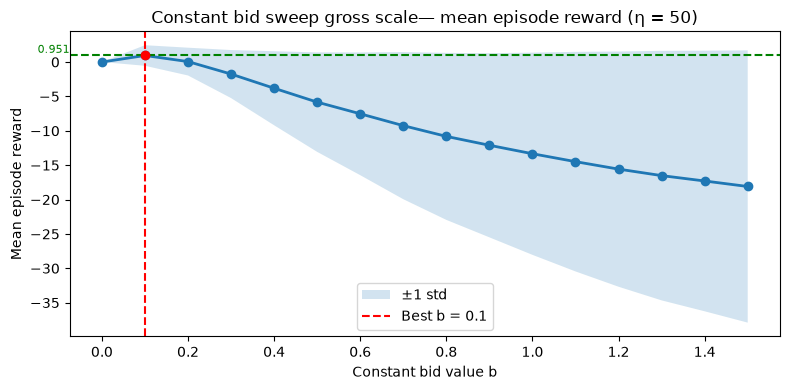

Best b = 0.1  (mean reward = 0.9507)


In [4]:
mean_r   = constant_gross_summary.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_gross_summary.groupby("bid_value")["episode_reward"].std()
best_bid_gross = mean_r.idxmax()
best_reward_gross = mean_r.loc[best_bid_gross]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_gross, best_reward_gross, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axhline(best_reward_gross, color="green", linestyle="--")
ax.text(
    ax.get_xlim()[0],
    best_reward_gross,
    f"{best_reward_gross:.3f}",
    va="bottom",
    ha="right",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axvline(best_bid_gross, color="red", linestyle="--", label=f"Best b = {best_bid_gross:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep gross scale— mean episode reward (η = 50)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_gross_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_gross:.4g}  (mean reward = {best_reward_gross:.4f})")

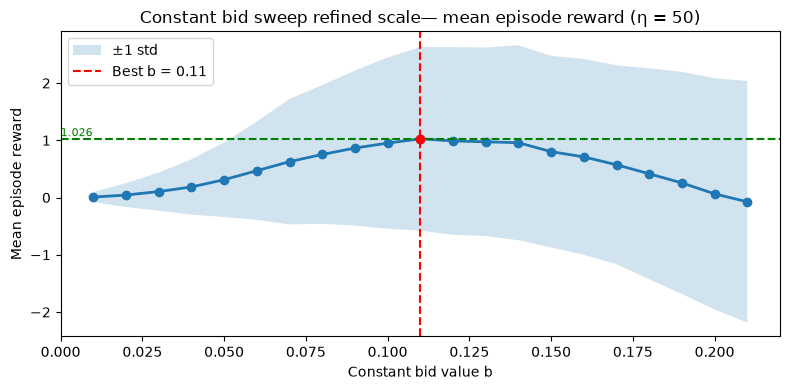

Best b = 0.11  (mean reward = 1.0259)


In [5]:
mean_r   = constant_refined_summary.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_refined_summary.groupby("bid_value")["episode_reward"].std()
best_bid_refined = mean_r.idxmax()
best_reward_refined = mean_r.loc[best_bid_refined]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_refined, best_reward_refined, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_bid_refined, color="red", linestyle="--", label=f"Best b = {best_bid_refined:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_refined,
    f"{best_reward_refined:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_refined, color="green", linestyle="--")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep refined scale— mean episode reward (η = 50)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_refined_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_refined:.4g}  (mean reward = {best_reward_refined:.4f})")

/tmp/ipykernel_1468519/157400307.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted], rotation=45, ha="right")


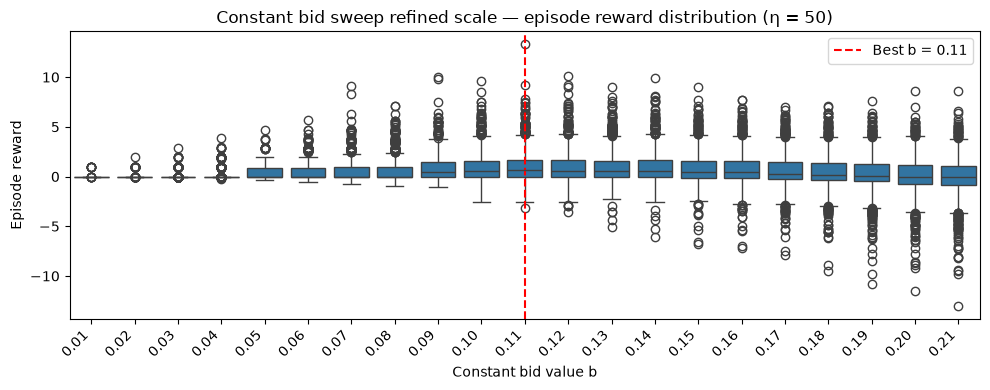

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
bids_sorted = sorted(constant_refined_summary["bid_value"].unique())
sns.boxplot(
    data=constant_refined_summary, x="bid_value", y="episode_reward",
    order=bids_sorted,
    ax=ax,
)
ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted], rotation=45, ha="right")
ax.axvline(bids_sorted.index(best_bid_refined), color="red", linestyle="--", label=f"Best b = {best_bid_refined:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Episode reward")
ax.set_title("Constant bid sweep refined scale — episode reward distribution (η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/constant_bid_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

#### η = 100

In [7]:
_f = f"{MAIN_DIR}/{SCEN}_eta100_constant_bid_sweep.csv"
constant_sweep_eta100 = pd.read_csv(_f) if os.path.exists(_f) else None
if constant_sweep_eta100 is not None:
    _best_b = constant_sweep_eta100.groupby("bid_value")["episode_reward"].mean().idxmax()
    constant_gross_summary_eta100 = constant_sweep_eta100[np.isclose(constant_sweep_eta100["bid_value"] * 10,
                                                                     np.round(constant_sweep_eta100["bid_value"] * 10))]
    constant_refined_summary_eta100 = constant_sweep_eta100[(constant_sweep_eta100["bid_value"] - _best_b).abs() <= 0.1 + 1e-9]
    print(f"{constant_sweep_eta100['bid_value'].nunique()} bid values × {constant_sweep_eta100['seed'].nunique()} campaigns")
else:
    print("η = 100: constant bid sweep not available yet")

151 bid values × 1000 campaigns


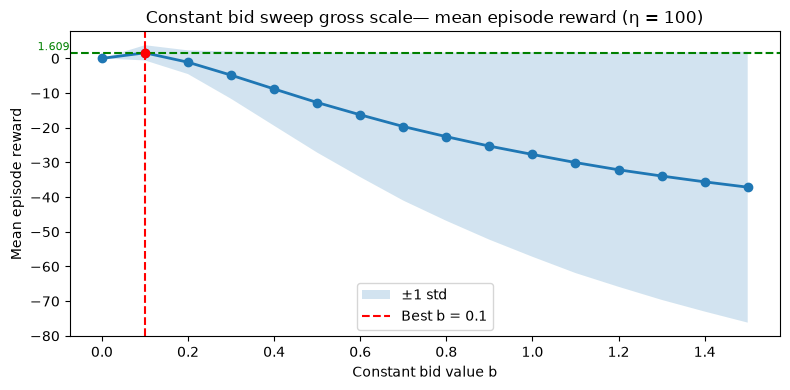

Best b = 0.1  (mean reward = 1.6091)


In [8]:
if constant_sweep_eta100 is not None:
    mean_r   = constant_gross_summary_eta100.groupby("bid_value")["episode_reward"].mean()
    std_r    = constant_gross_summary_eta100.groupby("bid_value")["episode_reward"].std()
    best_bid_gross_eta100 = mean_r.idxmax()
    best_reward_gross_eta100 = mean_r.loc[best_bid_gross_eta100]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
    ax.scatter(best_bid_gross_eta100, best_reward_gross_eta100, color="red", zorder=5)
    ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
    ax.axhline(best_reward_gross_eta100, color="green", linestyle="--")
    ax.text(
        ax.get_xlim()[0],
        best_reward_gross_eta100,
        f"{best_reward_gross_eta100:.3f}",
        va="bottom",
        ha="right",
        color="green",
        fontsize=8,
        backgroundcolor="none",
    )
    ax.axvline(best_bid_gross_eta100, color="red", linestyle="--", label=f"Best b = {best_bid_gross_eta100:.4g}")
    ax.set_xlabel("Constant bid value b")
    ax.set_ylabel("Mean episode reward")
    ax.set_title("Constant bid sweep gross scale— mean episode reward (η = 100)")
    ax.legend()
    plt.tight_layout()
    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/constant_bid_sweep_gross_mean_eta100.pdf", bbox_inches="tight")
    plt.show()
    print(f"Best b = {best_bid_gross_eta100:.4g}  (mean reward = {best_reward_gross_eta100:.4f})")
else:
    print("η = 100: constant bid sweep not available yet")

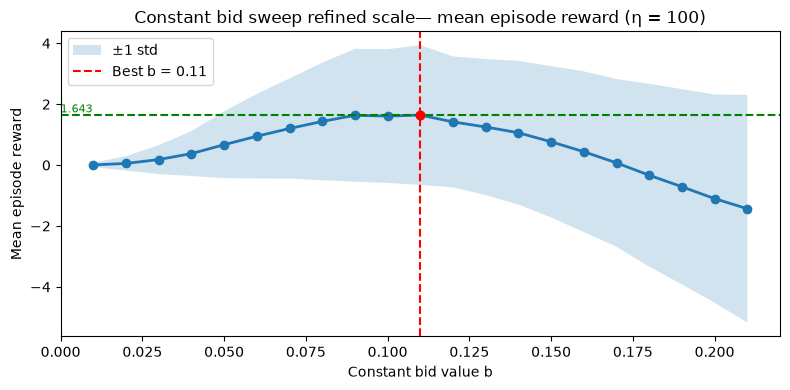

Best b = 0.11  (mean reward = 1.6427)


In [9]:
if constant_sweep_eta100 is not None:
    mean_r   = constant_refined_summary_eta100.groupby("bid_value")["episode_reward"].mean()
    std_r    = constant_refined_summary_eta100.groupby("bid_value")["episode_reward"].std()
    best_bid_refined_eta100 = mean_r.idxmax()
    best_reward_refined_eta100 = mean_r.loc[best_bid_refined_eta100]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
    ax.scatter(best_bid_refined_eta100, best_reward_refined_eta100, color="red", zorder=5)
    ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
    ax.axvline(best_bid_refined_eta100, color="red", linestyle="--", label=f"Best b = {best_bid_refined_eta100:.4g}")
    ax.text(
        ax.get_xlim()[0],
        best_reward_refined_eta100,
        f"{best_reward_refined_eta100:.3f}",
        va="bottom",
        ha="left",
        color="green",
        fontsize=8,
        backgroundcolor="none",
    )
    ax.axhline(best_reward_refined_eta100, color="green", linestyle="--")
    ax.set_xlabel("Constant bid value b")
    ax.set_ylabel("Mean episode reward")
    ax.set_title("Constant bid sweep refined scale— mean episode reward (η = 100)")
    ax.legend()
    plt.tight_layout()
    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/constant_bid_sweep_refined_mean_eta100.pdf", bbox_inches="tight")
    plt.show()
    print(f"Best b = {best_bid_refined_eta100:.4g}  (mean reward = {best_reward_refined_eta100:.4f})")
else:
    print("η = 100: constant bid sweep not available yet")

/tmp/ipykernel_1468519/1987852873.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted_eta100], rotation=45, ha="right")


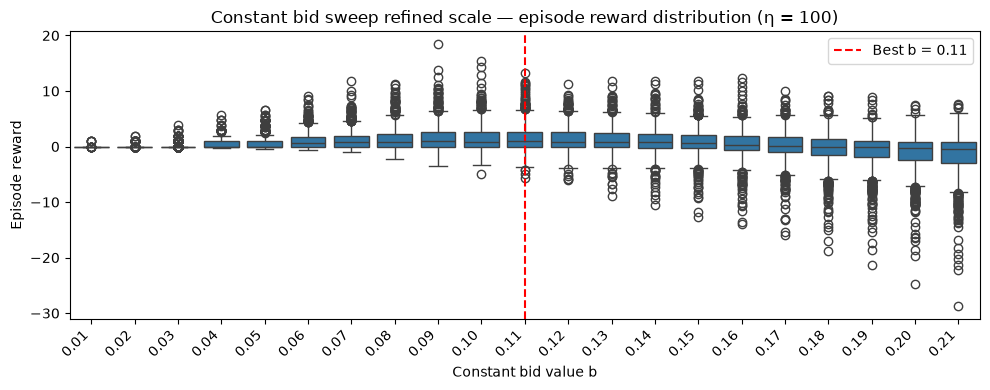

In [10]:
if constant_sweep_eta100 is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    bids_sorted_eta100 = sorted(constant_refined_summary_eta100["bid_value"].unique())
    sns.boxplot(
        data=constant_refined_summary_eta100, x="bid_value", y="episode_reward",
        order=bids_sorted_eta100,
        ax=ax,
    )
    ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted_eta100], rotation=45, ha="right")
    ax.axvline(bids_sorted_eta100.index(best_bid_refined_eta100), color="red", linestyle="--", label=f"Best b = {best_bid_refined_eta100:.4g}")
    ax.set_xlabel("Constant bid value b")
    ax.set_ylabel("Episode reward")
    ax.set_title("Constant bid sweep refined scale — episode reward distribution (η = 100)")
    ax.legend()
    plt.tight_layout()
    plt.savefig("plots/constant_bid_sweep_dist_eta100.pdf", bbox_inches="tight")
    plt.show()
else:
    print("η = 100: constant bid sweep not available yet")

## Shading α sweep

`ShadingPolicy` bids α times the value of the display estimated with M = 20 Monte-Carlo rollouts, α ∈ {0.1, …, 1}, each
value evaluated on the 1 000 test campaigns; mean ± std of the episode reward and per-campaign distribution.

#### η = 50

In [11]:
shading_summary_eta50 = pd.read_csv(f"{MAIN_DIR}/{SCEN}_eta50_shading_alpha_sweep.csv")   # alpha, seed, episode_reward
print(f"{shading_summary_eta50['alpha'].nunique()} α values × {shading_summary_eta50['seed'].nunique()} campaigns")

10 α values × 1000 campaigns


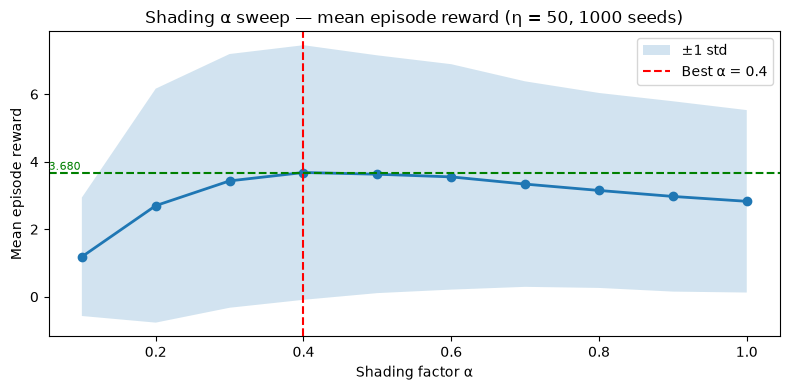

Best α = 0.4  (mean reward = 3.6797)


In [12]:
mean_r = shading_summary_eta50.groupby("alpha")["episode_reward"].mean()
std_r  = shading_summary_eta50.groupby("alpha")["episode_reward"].std()
best_alpha = mean_r.idxmax()
best_reward_eta50 = mean_r.loc[best_alpha]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha, color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_eta50,
    f"{best_reward_eta50:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_eta50, color="green", linestyle="--")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha:.4g}  (mean reward = {best_reward_eta50:.4f})")

/tmp/ipykernel_1468519/2157213291.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


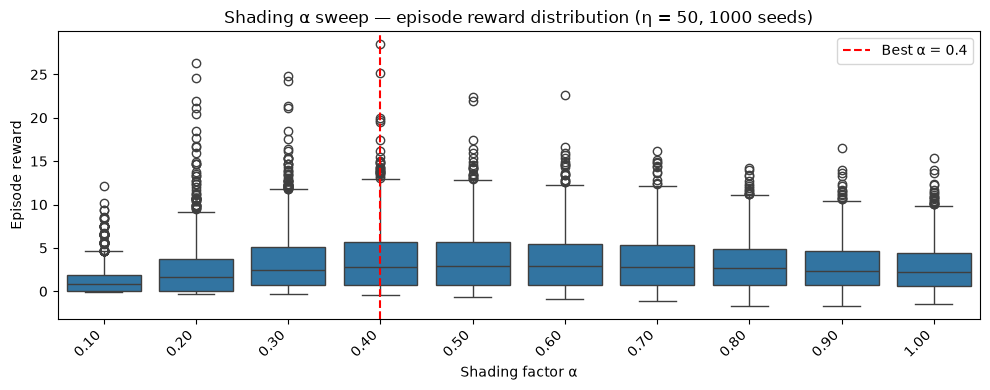

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=shading_summary_eta50, x="alpha", y="episode_reward",
    order=sorted(shading_summary_eta50["alpha"].unique()),
    ax=ax,
)
alphas_sorted = sorted(shading_summary_eta50["alpha"].unique())
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.axvline(alphas_sorted.index(best_alpha), color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

#### η = 100

In [14]:
_f = f"{MAIN_DIR}/{SCEN}_eta100_shading_alpha_sweep.csv"
shading_summary_eta100 = pd.read_csv(_f) if os.path.exists(_f) else None   # alpha, seed, episode_reward
if shading_summary_eta100 is not None:
    print(f"{shading_summary_eta100['alpha'].nunique()} α values × {shading_summary_eta100['seed'].nunique()} campaigns")
else:
    print("η = 100: Shading α sweep not available yet")

10 α values × 1000 campaigns


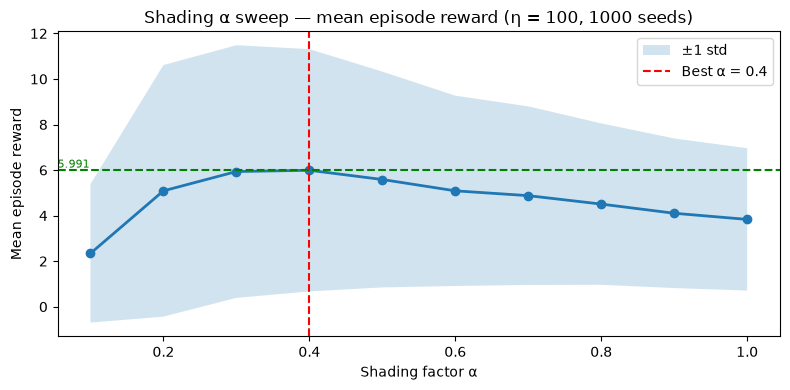

Best α = 0.4  (mean reward = 5.9908)


In [15]:
if shading_summary_eta100 is not None:
    mean_r = shading_summary_eta100.groupby("alpha")["episode_reward"].mean()
    std_r  = shading_summary_eta100.groupby("alpha")["episode_reward"].std()
    best_alpha_eta100 = mean_r.idxmax()
    best_reward_eta100 = mean_r.loc[best_alpha_eta100]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
    ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
    ax.axvline(best_alpha_eta100, color="red", linestyle="--", label=f"Best α = {best_alpha_eta100:.4g}")
    ax.text(
        ax.get_xlim()[0],
        best_reward_eta100,
        f"{best_reward_eta100:.3f}",
        va="bottom",
        ha="left",
        color="green",
        fontsize=8,
        backgroundcolor="none",
    )
    ax.axhline(best_reward_eta100, color="green", linestyle="--")
    ax.set_xlabel("Shading factor α")
    ax.set_ylabel("Mean episode reward")
    ax.set_title("Shading α sweep — mean episode reward (η = 100, 1000 seeds)")
    ax.legend()
    plt.tight_layout()
    plt.savefig("plots/shading_alpha_sweep_mean_eta100.pdf", bbox_inches="tight")
    plt.show()
    print(f"Best α = {best_alpha_eta100:.4g}  (mean reward = {best_reward_eta100:.4f})")
else:
    print("η = 100: Shading α sweep not available yet")

/tmp/ipykernel_1468519/2243846176.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted_eta100], rotation=45, ha="right")


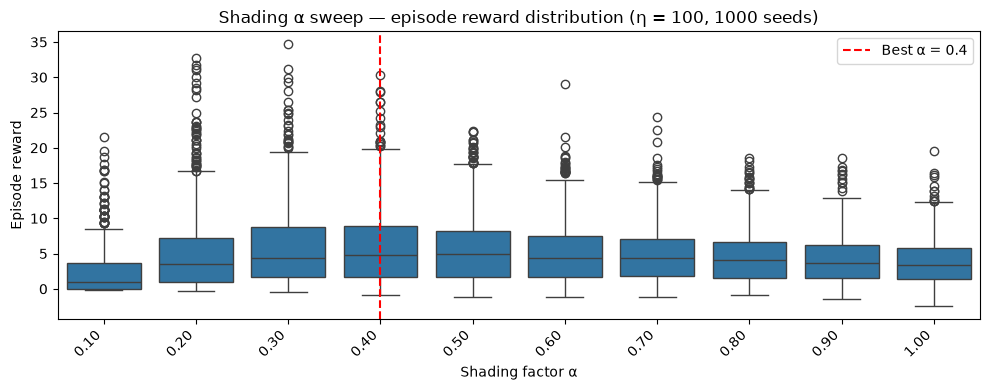

In [16]:
if shading_summary_eta100 is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(
        data=shading_summary_eta100, x="alpha", y="episode_reward",
        order=sorted(shading_summary_eta100["alpha"].unique()),
        ax=ax,
    )
    alphas_sorted_eta100 = sorted(shading_summary_eta100["alpha"].unique())
    ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted_eta100], rotation=45, ha="right")
    ax.axvline(alphas_sorted_eta100.index(best_alpha_eta100), color="red", linestyle="--", label=f"Best α = {best_alpha_eta100:.4g}")
    ax.set_xlabel("Shading factor α")
    ax.set_ylabel("Episode reward")
    ax.set_title("Shading α sweep — episode reward distribution (η = 100, 1000 seeds)")
    ax.legend()
    plt.tight_layout()
    plt.savefig("plots/shading_alpha_sweep_dist_eta100.pdf", bbox_inches="tight")
    plt.show()
else:
    print("η = 100: Shading α sweep not available yet")

## 1. Load results

Per-step logs of every policy. For the per-step plots, the 3 trainings of each RL algorithm are pooled into one policy
(campaign ids made distinct); for the scores (episode reward per campaign, used by the tables and by rliable), each RL
algorithm gets the mean of its 3 trainings on every campaign.

In [17]:
manifest = json.load(open(f"{MAIN_DIR}/manifest.json"))
RL = ("PPO", "TD3", "SAC")


def load_results(eta: int):
    """Per-step frame for the plots (RL trainings pooled, campaign ids made distinct) and scores per campaign (RL = mean
    of the 3 trainings); an RL algorithm with fewer than 3 trainings is left out of both. (None, None) if no file yet."""
    todo = manifest[f"eta{eta}"]["missing_or_incomplete"]
    if todo:
        print(f"η = {eta}, not available yet:", "; ".join(todo))
    f = f"{MAIN_DIR}/{SCEN}_eta{eta}_results_final.csv.gz"
    if not os.path.exists(f):
        return None, None
    df_raw = pd.read_csv(f)
    m = df_raw["policy"].str.extract(r"^(PPO|TD3|SAC) \(training (\d)\)$")
    n_trainings = m.dropna().groupby(0)[1].nunique()
    partial = [a for a in RL if 0 < n_trainings.get(a, 0) < 3]
    keep = ~m[0].isin(partial)
    df_raw, m = df_raw[keep], m[keep]
    df = df_raw.copy()
    rl = m[0].notna()
    df.loc[rl, "seed"] = df.loc[rl, "seed"] + 1000 * (m.loc[rl, 1].astype(int) - 1)
    df.loc[rl, "policy"] = m.loc[rl, 0]
    raw = score_matrix(df_raw)
    scores = {p: v for p, v in raw.items() if not p.startswith(tuple(f"{a} (training" for a in RL))}
    for a in RL:
        tr = [v for p, v in raw.items() if p.startswith(f"{a} (training")]
        if len(tr) == 3:
            scores[a] = np.mean(tr, axis=0)
    return df, scores


df_eta50, scores_eta50 = load_results(50)
df_eta100, scores_eta100 = load_results(100)

Policies, number of campaigns and mean number of auction opportunities per campaign (the horizon is exponential with mean
η, so a campaign has about η auctions on average).

In [18]:
from IPython.display import display

for eta, df in ((50, df_eta50), (100, df_eta100)):
    if df is None:
        print(f"η = {eta}: not available yet")
        continue
    _ep = df.groupby(["policy", "seed"])["step"].max().groupby("policy")
    display(pd.DataFrame({"campaigns": _ep.size(), "mean auctions per campaign": _ep.mean().round(1)})
            .rename_axis(f"policy (η = {eta})"))

,campaigns,mean auctions per campaign
policy (η = 50),,
Constant,1000,47.7
FiPla,1000,47.7
GreedyMyopic,1000,47.7
"MPC(H=10, M=60)",1000,47.7
"MPC(H=25, M=60)",1000,47.7
"MPC(H=25, M=60, α_cont=0.4)",1000,47.7
"MPC(H=25, M=80)",1000,47.7
"MPC(H=35, M=60)",1000,47.7
"MPC(H=35, M=60, α_cont=0.4)",1000,47.7


,campaigns,mean auctions per campaign
policy (η = 100),,
Constant,1000,95.4
FiPla,1000,95.4
GreedyMyopic,1000,95.4
"MPC(H=10, M=60)",1000,95.4
"MPC(H=25, M=60)",1000,95.4
"MPC(H=25, M=60, α_cont=0.4)",1000,95.4
"MPC(H=25, M=80)",1000,95.4
"MPC(H=35, M=60)",1000,95.4
"MPC(H=35, M=60, α_cont=0.4)",1000,95.4


## 2. Benchmark Results

### A. Tables

Mean episode reward ± 95% CI over the 1 000 test campaigns, paired differences with FiPla and with Shading(best α, M=40) of the same η
(± 95% CI). RL rows: mean of the 3 trainings per campaign.

In [19]:
from IPython.display import display, HTML


def _ci95(x):
    return 1.96 * np.std(x, ddof=1) / np.sqrt(len(x))


def _score_df(scores: dict) -> pd.DataFrame:
    rows = []
    shading = next((q for q in scores if q.startswith("Shading(")), None)   # η = 50: α = 0.4; η = 100: best α of its sweep
    for p, v in scores.items():
        row = {"Policy": p, "Mean reward": float(v.mean()), "± 95% CI": _ci95(v), "Std": float(v.std()), "Seeds": len(v)}
        for ref in ("FiPla", shading):
            if ref in scores and p != ref:
                d = v - scores[ref]
                row[f"Δ vs {ref}"] = f"{d.mean():+.3f} ± {_ci95(d):.3f}"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("Mean reward", ascending=False).reset_index(drop=True)


def _display_score_table(scores: dict, title: str):
    df = _score_df(scores)
    display(HTML(f"<h4 style='margin-bottom:4px'>{title}</h4>"))
    display(
        df.style
        .format({"Mean reward": "{:.4f}", "± 95% CI": "{:.4f}", "Std": "{:.4f}"}, na_rep="—")
        .bar(subset=["Mean reward"], color="#4C72B0", vmin=0)
        .set_properties(**{"text-align": "center"})
        .hide(axis="index")
    )


_display_score_table(scores_eta50, "η = 50")
if scores_eta100:
    _display_score_table(scores_eta100, "η = 100")
else:
    print("η = 100: not available yet")

Policy,Mean reward,± 95% CI,Std,Seeds,Δ vs FiPla,"Δ vs Shading(α=0.4, M=40)"
"MPC(H=35, M=60, α_cont=0.4)",4.2357,0.2706,4.3636,1000,+1.415 ± 0.192,+0.556 ± 0.125
"MPC(H=25, M=60, α_cont=0.4)",4.1694,0.2617,4.2199,1000,+1.348 ± 0.183,+0.490 ± 0.121
"MPC(H=35, M=60)",4.1299,0.2666,4.2995,1000,+1.309 ± 0.188,+0.450 ± 0.121
"MPC(H=25, M=80)",4.1272,0.2575,4.1521,1000,+1.306 ± 0.178,+0.447 ± 0.121
"MPC(H=25, M=60)",4.1084,0.2613,4.2137,1000,+1.287 ± 0.179,+0.429 ± 0.124
"MPC(H=10, M=60)",3.6974,0.2185,3.5230,1000,+0.876 ± 0.144,+0.018 ± 0.124
"Shading(α=0.4, M=40)",3.6798,0.2336,3.7676,1000,+0.859 ± 0.158,—
PPO,2.9649,0.1816,2.9289,1000,+0.144 ± 0.121,-0.715 ± 0.122
GreedyMyopic,2.8264,0.1674,2.7001,1000,+0.005 ± 0.083,-0.853 ± 0.157
FiPla,2.8211,0.1603,2.5844,1000,—,-0.859 ± 0.158


Policy,Mean reward,± 95% CI,Std,Seeds,Δ vs FiPla,"Δ vs Shading(α=0.4, M=40)"
"MPC(H=35, M=60, α_cont=0.4)",7.1103,0.3986,6.4283,1000,+3.245 ± 0.308,+1.265 ± 0.217
"MPC(H=35, M=60)",6.8011,0.3792,6.1150,1000,+2.936 ± 0.284,+0.956 ± 0.195
"MPC(H=25, M=80)",6.7884,0.3675,5.9267,1000,+2.923 ± 0.270,+0.943 ± 0.190
"MPC(H=25, M=60, α_cont=0.4)",6.7042,0.3541,5.7105,1000,+2.839 ± 0.261,+0.859 ± 0.195
"MPC(H=25, M=60)",6.6587,0.3710,5.9824,1000,+2.793 ± 0.281,+0.814 ± 0.203
"Shading(α=0.4, M=40)",5.8452,0.3206,5.1700,1000,+1.980 ± 0.235,—
"MPC(H=10, M=60)",5.7046,0.2868,4.6242,1000,+1.839 ± 0.194,-0.141 ± 0.182
FiPla,3.8653,0.1899,3.0619,1000,—,-1.980 ± 0.235
GreedyMyopic,3.8331,0.1938,3.1246,1000,-0.032 ± 0.111,-2.012 ± 0.242
PPO,3.5549,0.1907,3.0752,1000,-0.310 ± 0.154,-2.290 ± 0.201


### B.Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 1000 seeds, with stratified bootstrap confidence intervals (rliable).

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/aggregate_metrics_eta50.pdf


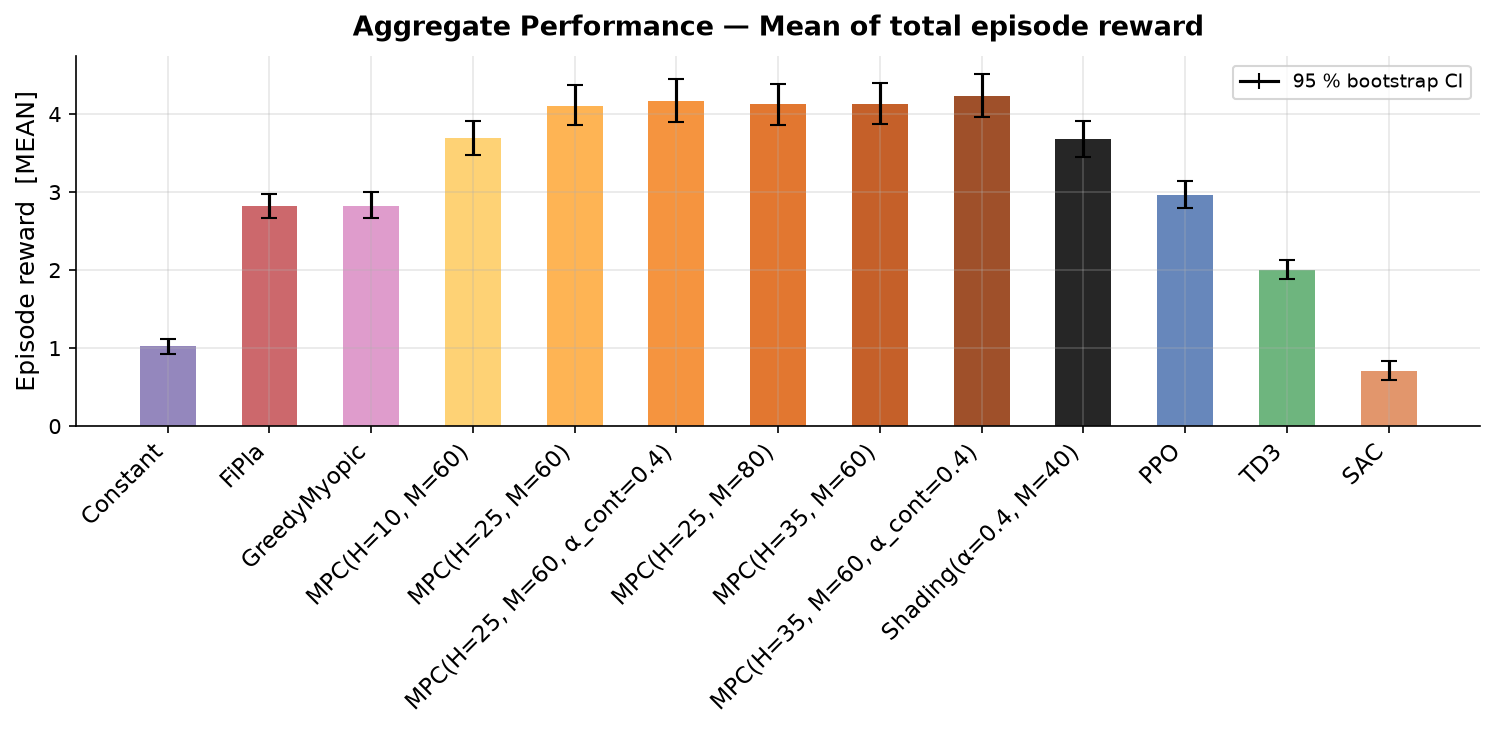

In [20]:
_ = plots.plot_aggregate_metrics(scores_eta50, metric="mean", normalize_by=None, filename="aggregate_metrics_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/aggregate_metrics_eta100.pdf


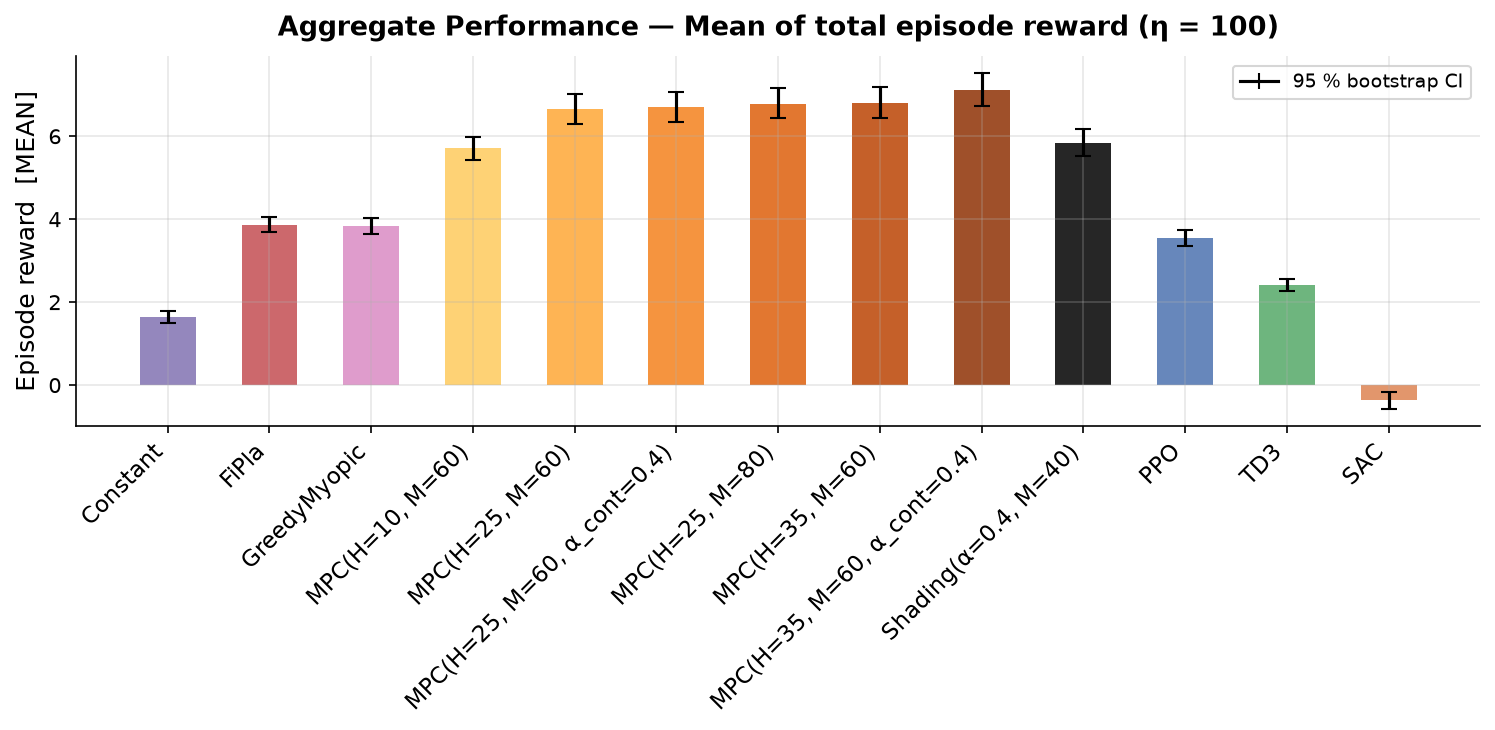

In [21]:
if scores_eta100:
    _ = plots.plot_aggregate_metrics(scores_eta100, metric="mean", normalize_by=None, filename="aggregate_metrics_eta100.pdf", title="Aggregate Performance — Mean of total episode reward (η = 100)")
else:
    print("η = 100: results not available yet")

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/performance_profiles_eta50.pdf


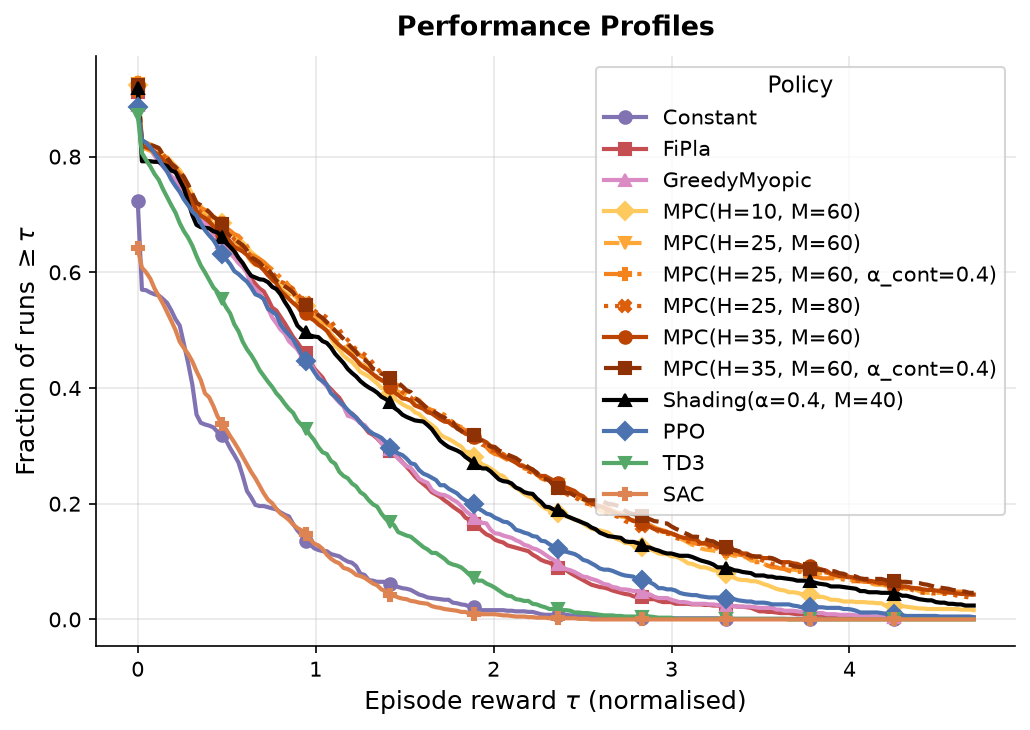

In [22]:
_ = plots.plot_performance_profiles(scores_eta50, filename="performance_profiles_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/performance_profiles_eta100.pdf


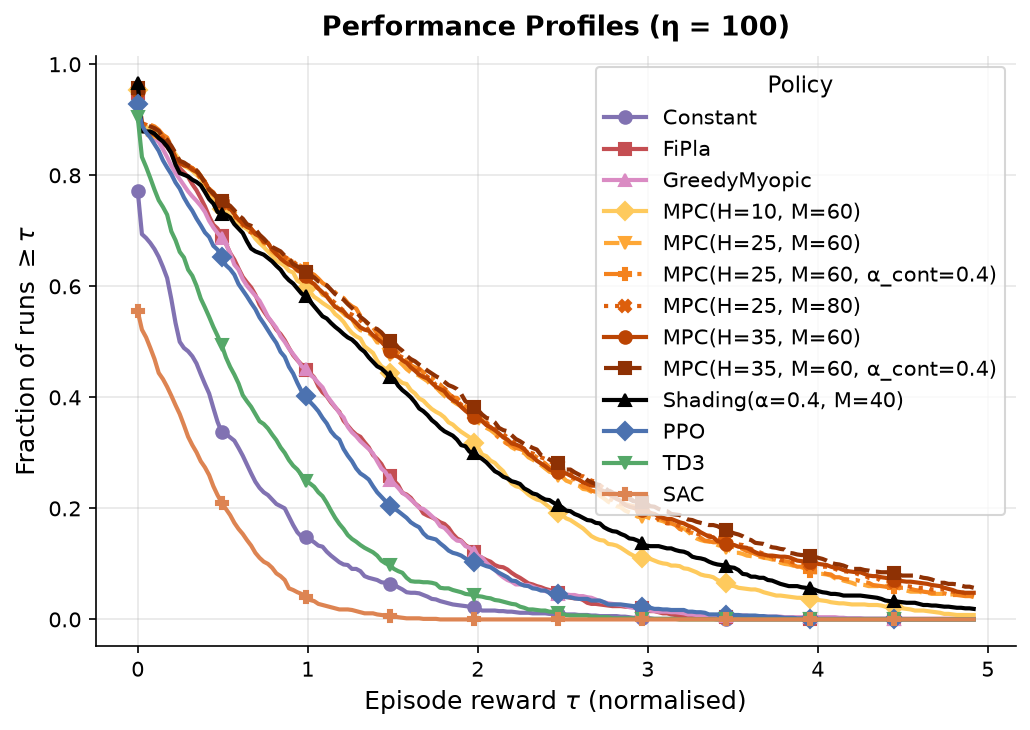

In [23]:
if scores_eta100:
    _ = plots.plot_performance_profiles(scores_eta100, filename="performance_profiles_eta100.pdf", title="Performance Profiles (η = 100)")
else:
    print("η = 100: results not available yet")

### Cumulative reward over time

Mean cumulative reward as a function of **normalised campaign time** (each episode's
time axis is rescaled to [0, 1] before averaging), across 1 000 seeds.
Shaded bands show ±1 standard deviation.

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/cumulative_reward_eta50.pdf


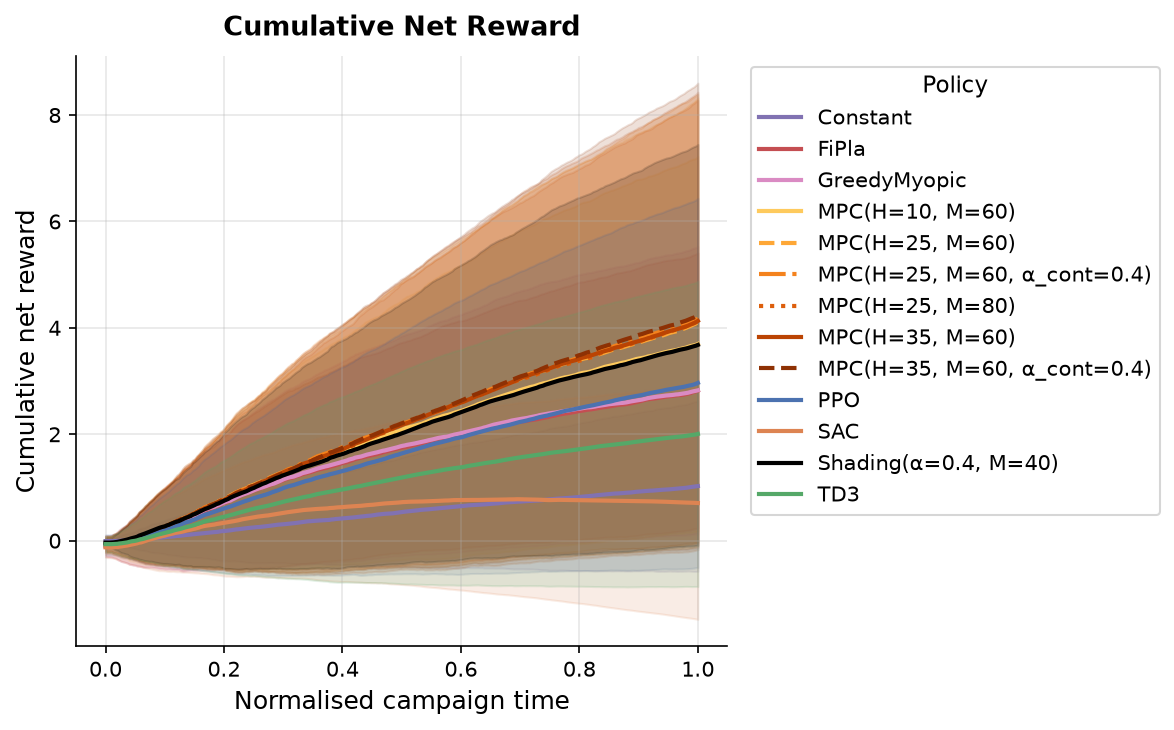

In [24]:
_ = plots.plot_cumulative_reward(df_eta50, filename="cumulative_reward_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/cumulative_reward_eta100.pdf


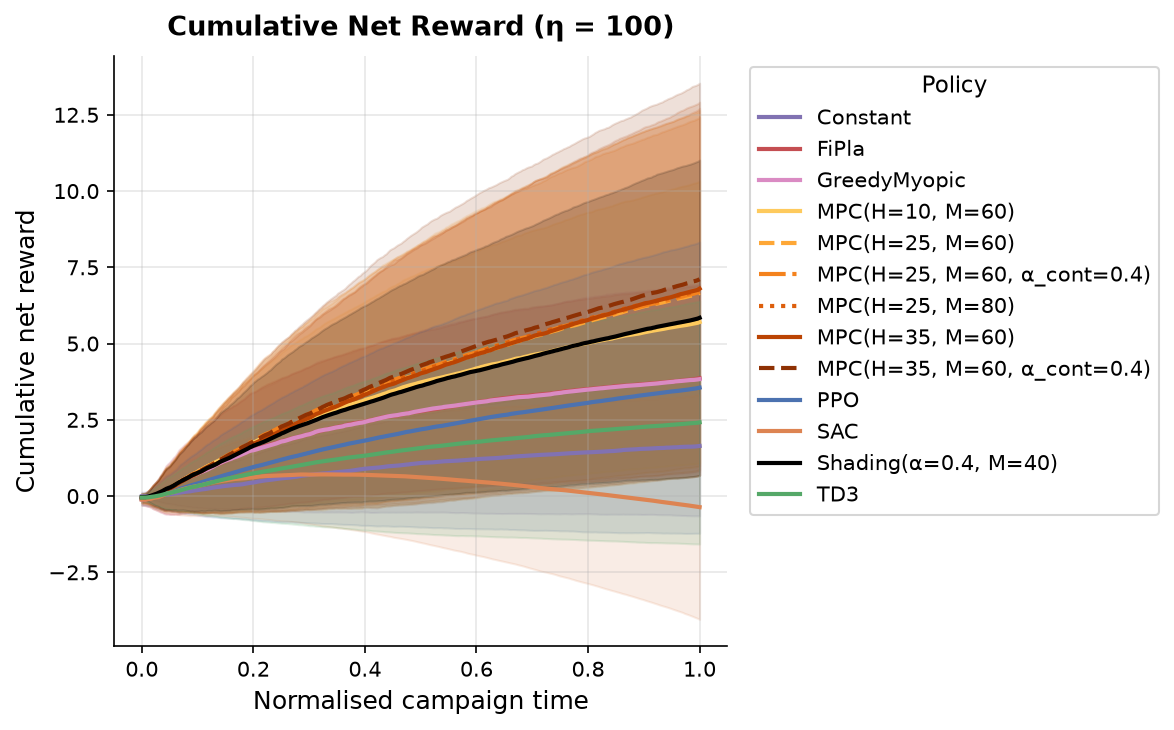

In [25]:
if df_eta100 is not None:
    _ = plots.plot_cumulative_reward(df_eta100, filename="cumulative_reward_eta100.pdf", title="Cumulative Net Reward (η = 100)")
else:
    print("η = 100: results not available yet")

### Episode reward distribution

Distribution of total episode reward across 1000 seeds for each policy.

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:421: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/reward_distribution_eta50.pdf


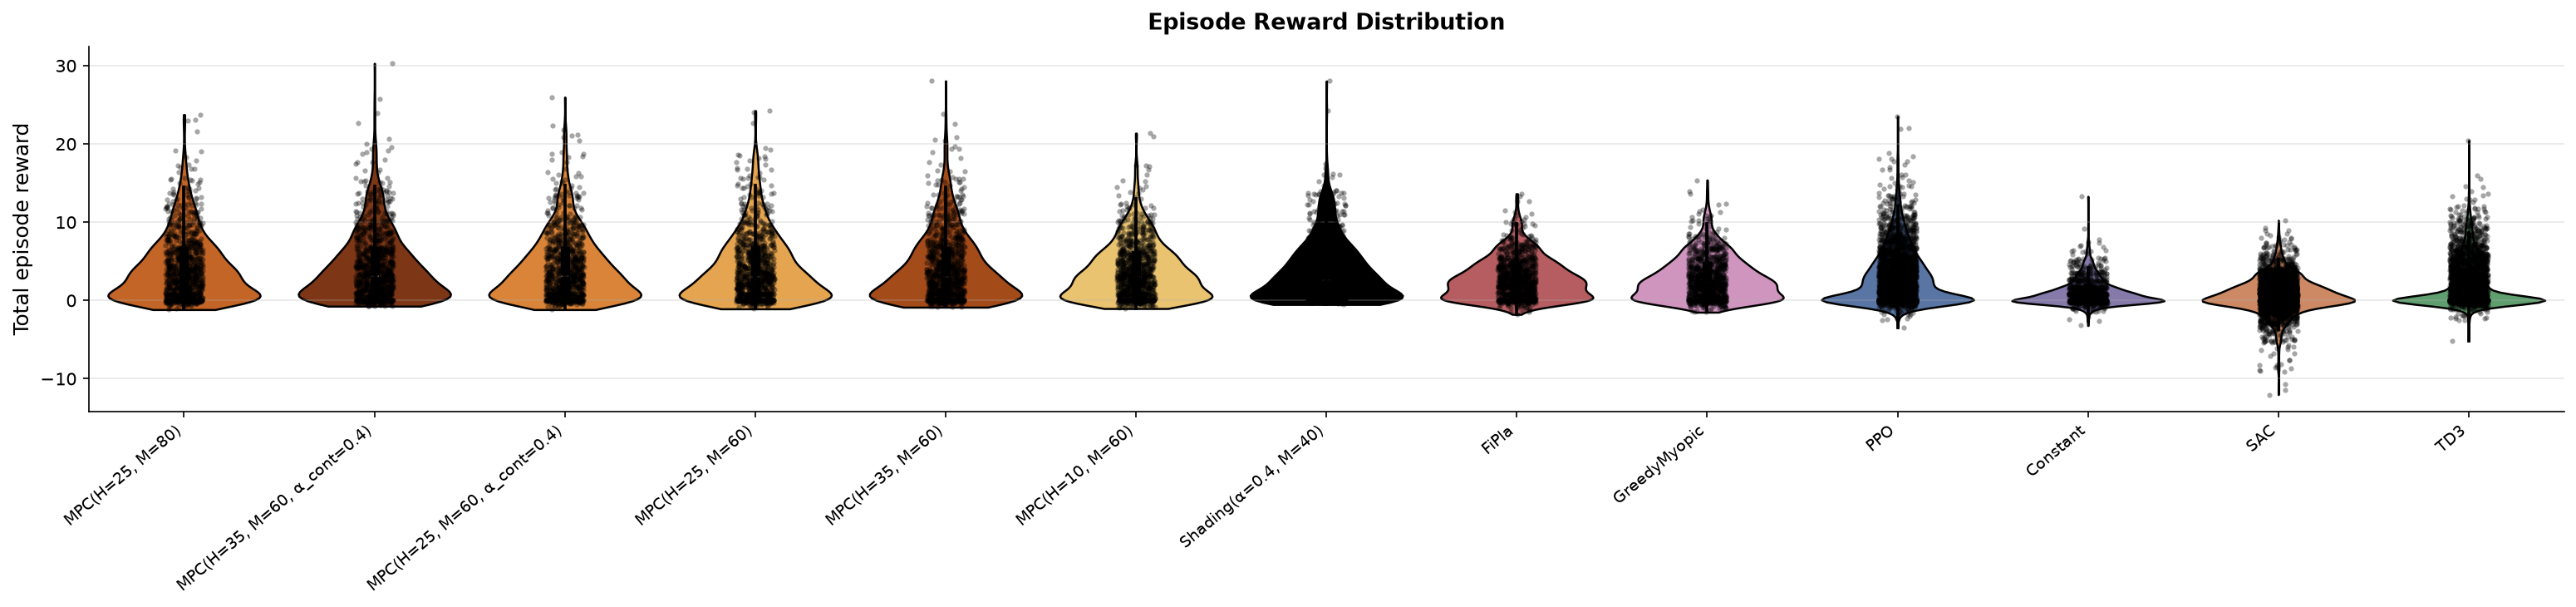

In [26]:
_ = plots.plot_reward_distribution(df_eta50, filename="reward_distribution_eta50.pdf")

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:421: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/reward_distribution_eta100.pdf


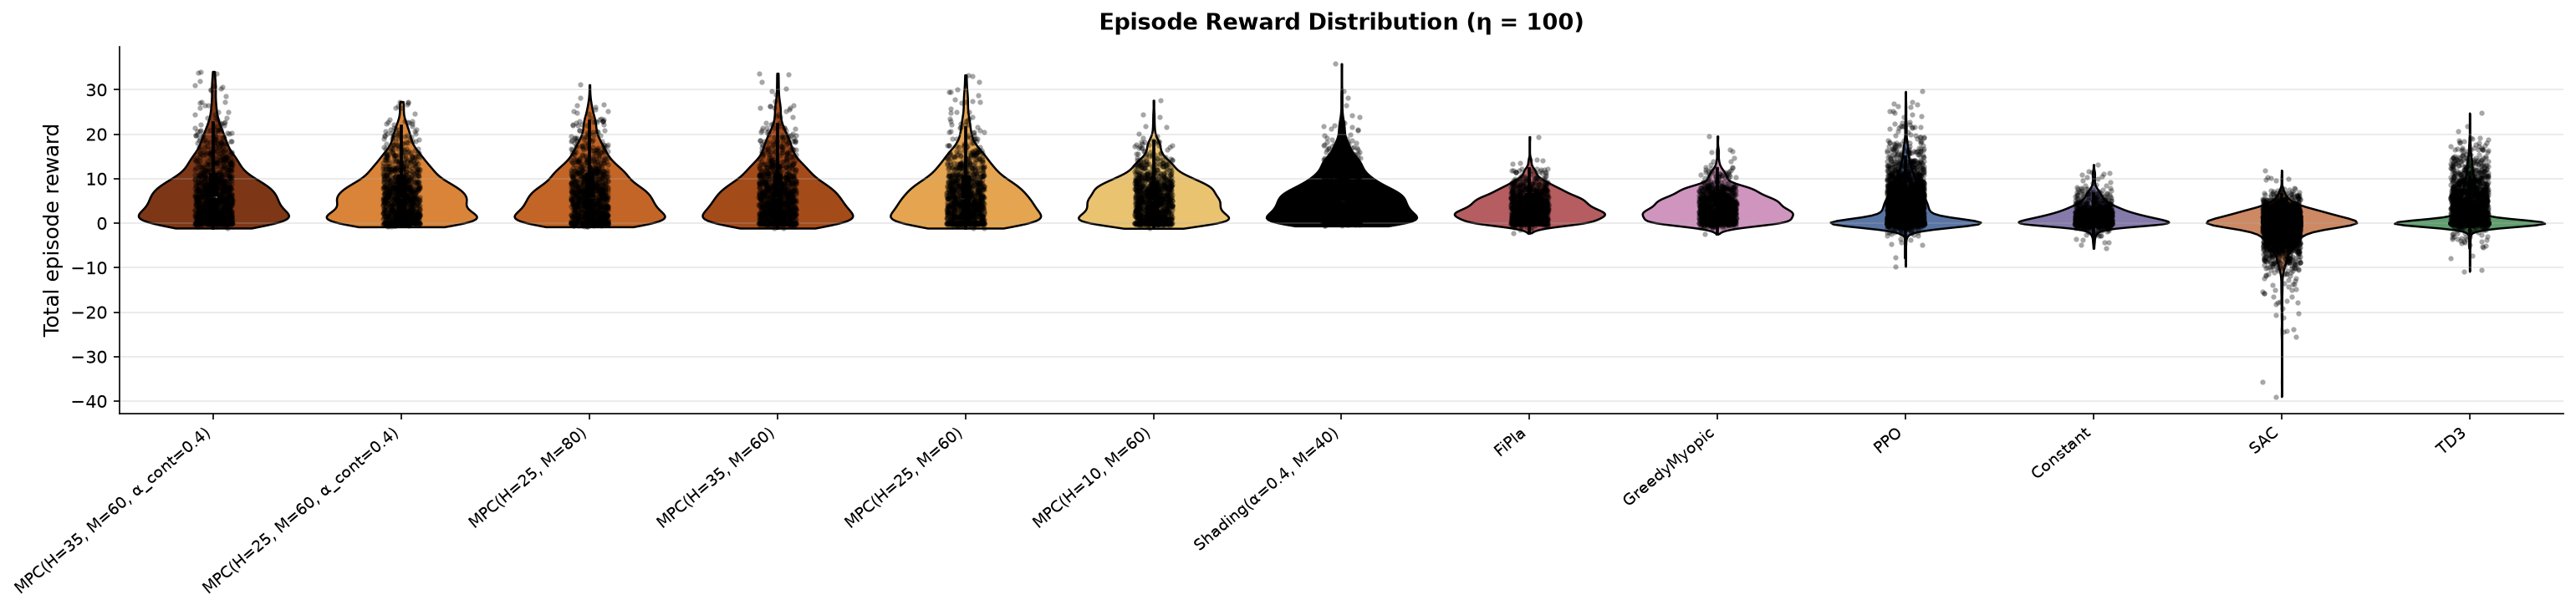

In [27]:
if df_eta100 is not None:
    _ = plots.plot_reward_distribution(df_eta100, filename="reward_distribution_eta100.pdf", title="Episode Reward Distribution (η = 100)")
else:
    print("η = 100: results not available yet")

### Context dynamics

Evolution of the context signal `ctx` and the expected reward over **normalised
campaign time** (rescaled to [0, 1] per seed), averaged across 1 000 seeds.
Illustrates how the survival kernel erodes the display value as the campaign progresses.

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/context_dynamics_eta50.pdf


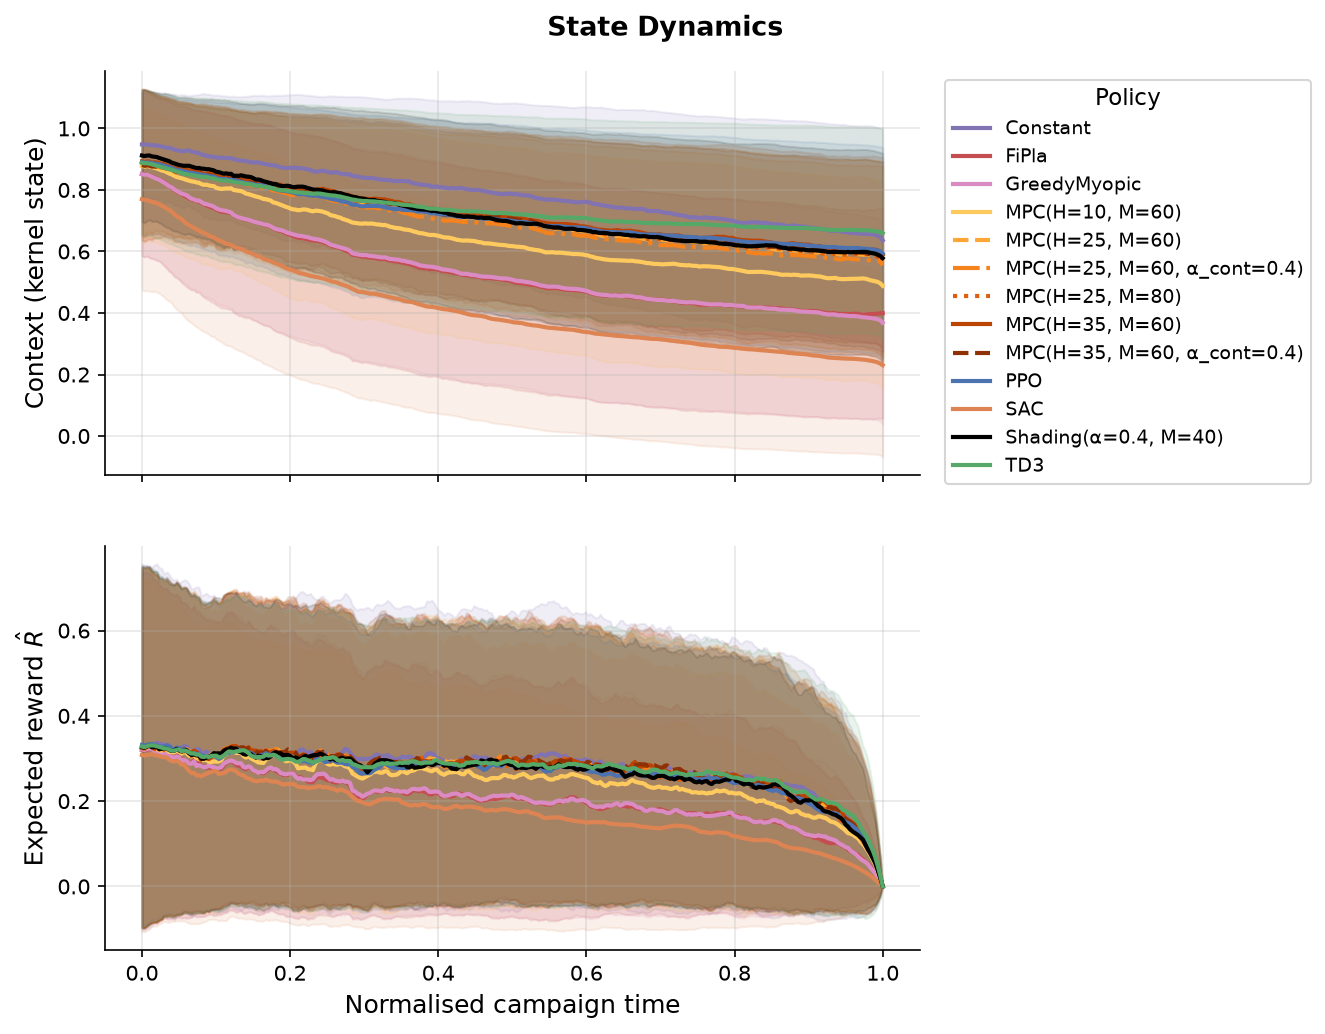

In [28]:
_ = plots.plot_context_dynamics(df_eta50, filename="context_dynamics_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/context_dynamics_eta100.pdf


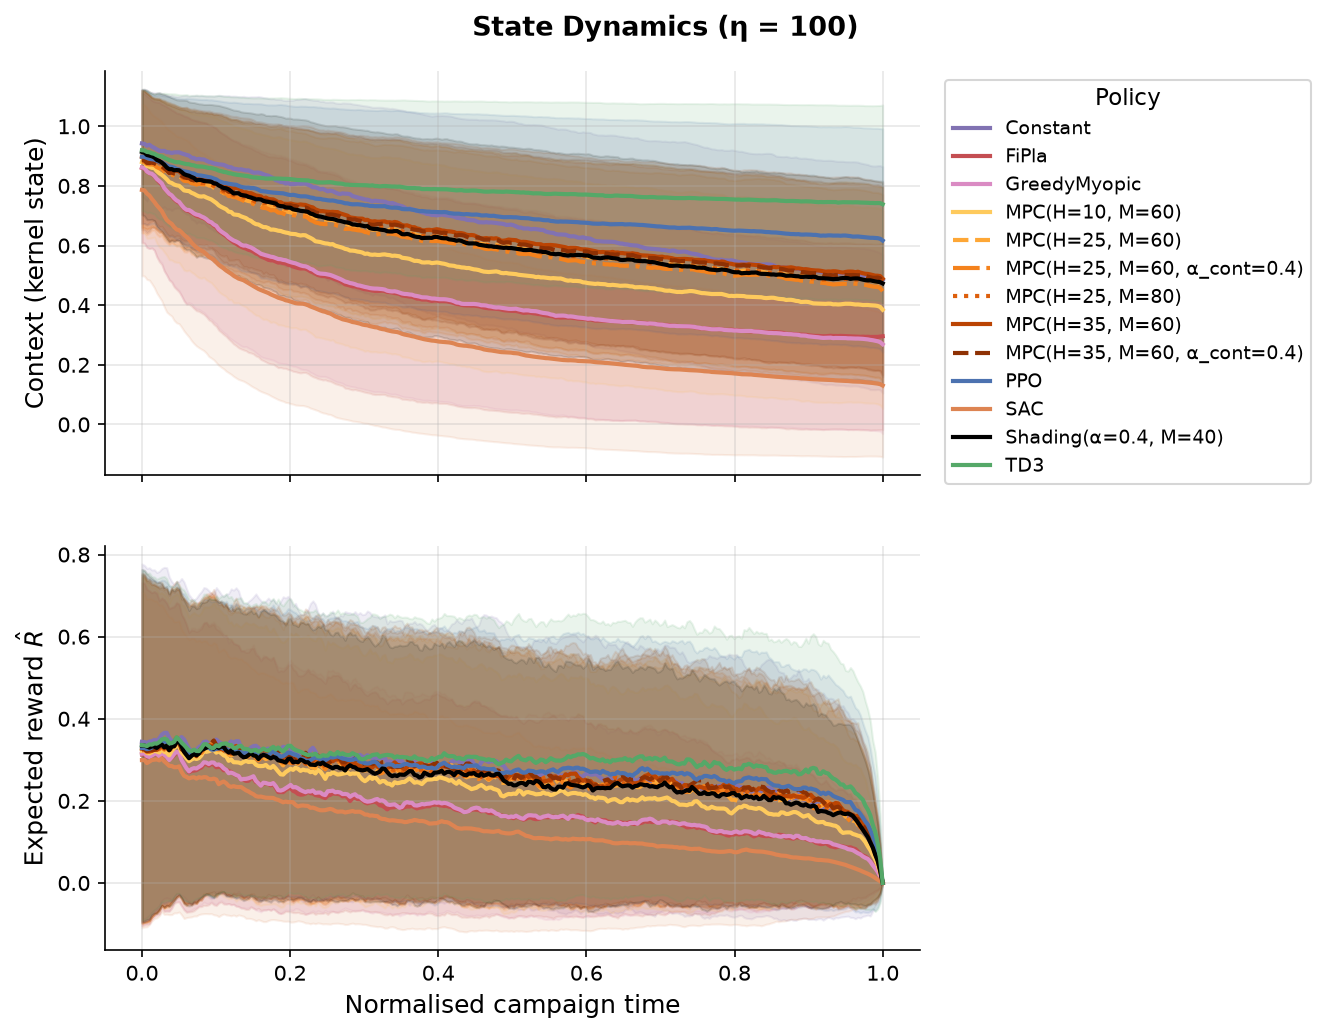

In [29]:
if df_eta100 is not None:
    _ = plots.plot_context_dynamics(df_eta100, filename="context_dynamics_eta100.pdf", title="State Dynamics (η = 100)")
else:
    print("η = 100: results not available yet")

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true value.

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/bid_distributions_eta50.pdf


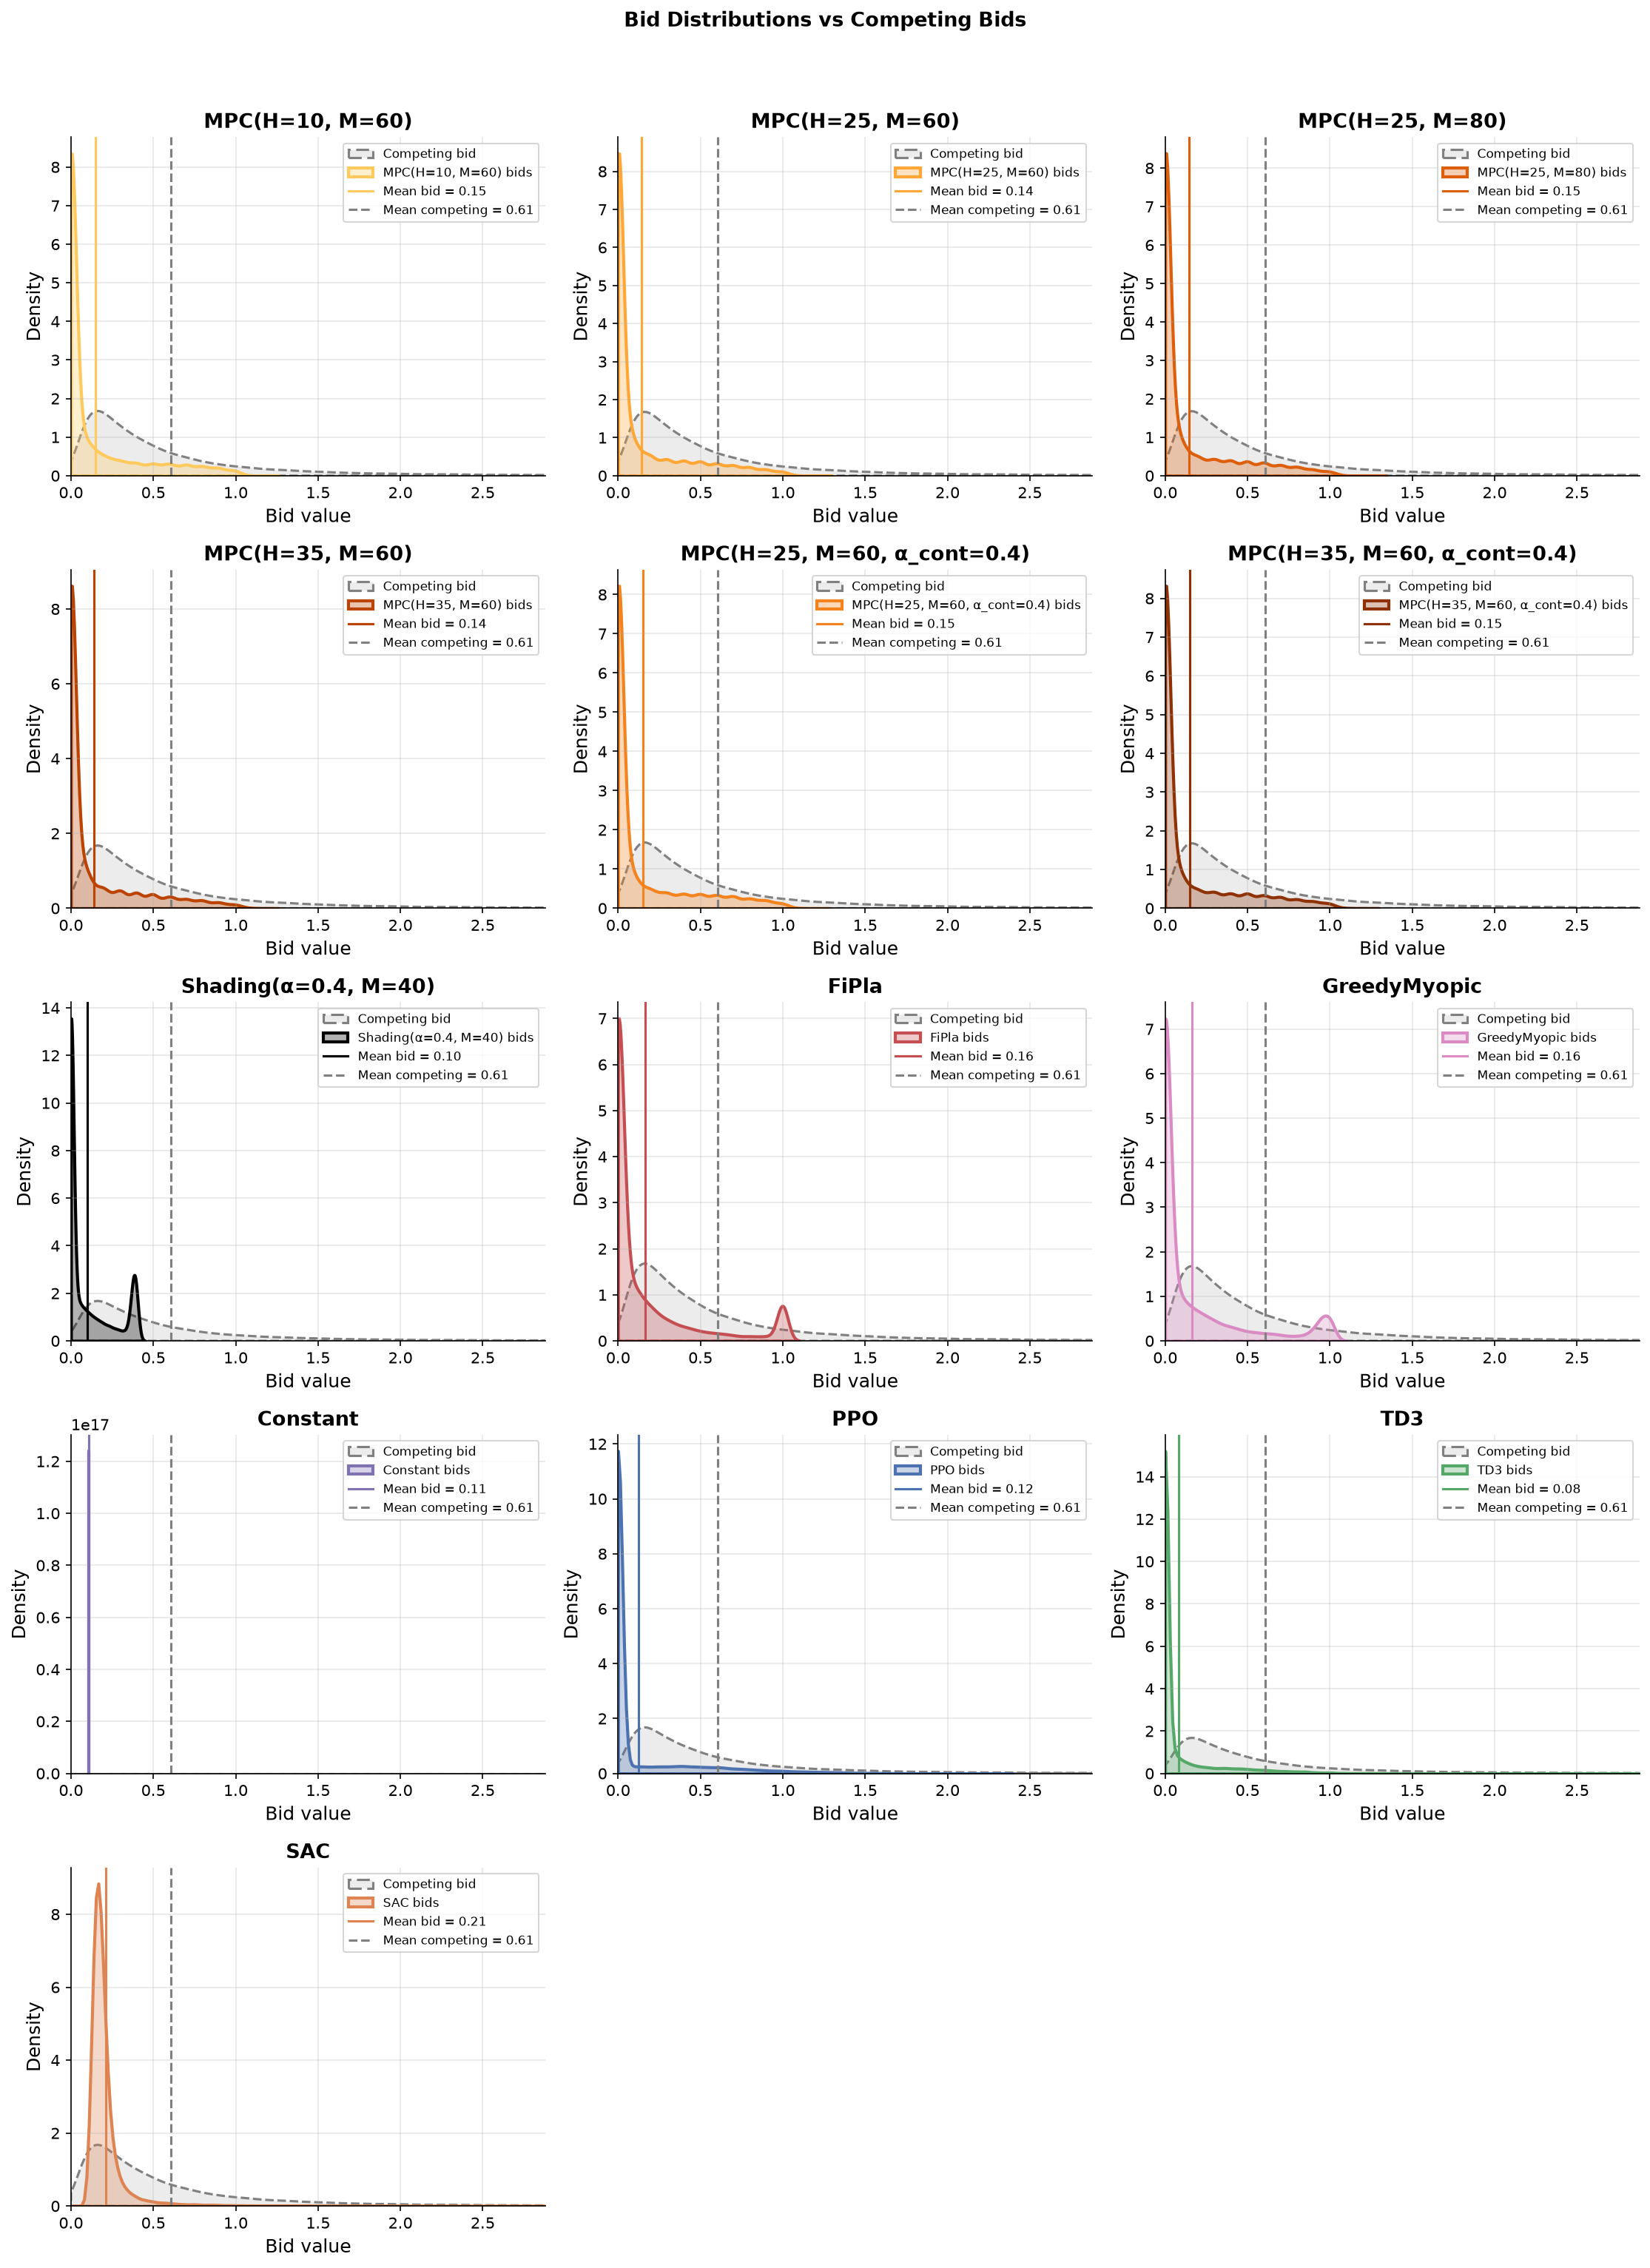

In [30]:
_ = plots.plot_bid_distributions(df_eta50, filename="bid_distributions_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/bid_distributions_eta100.pdf


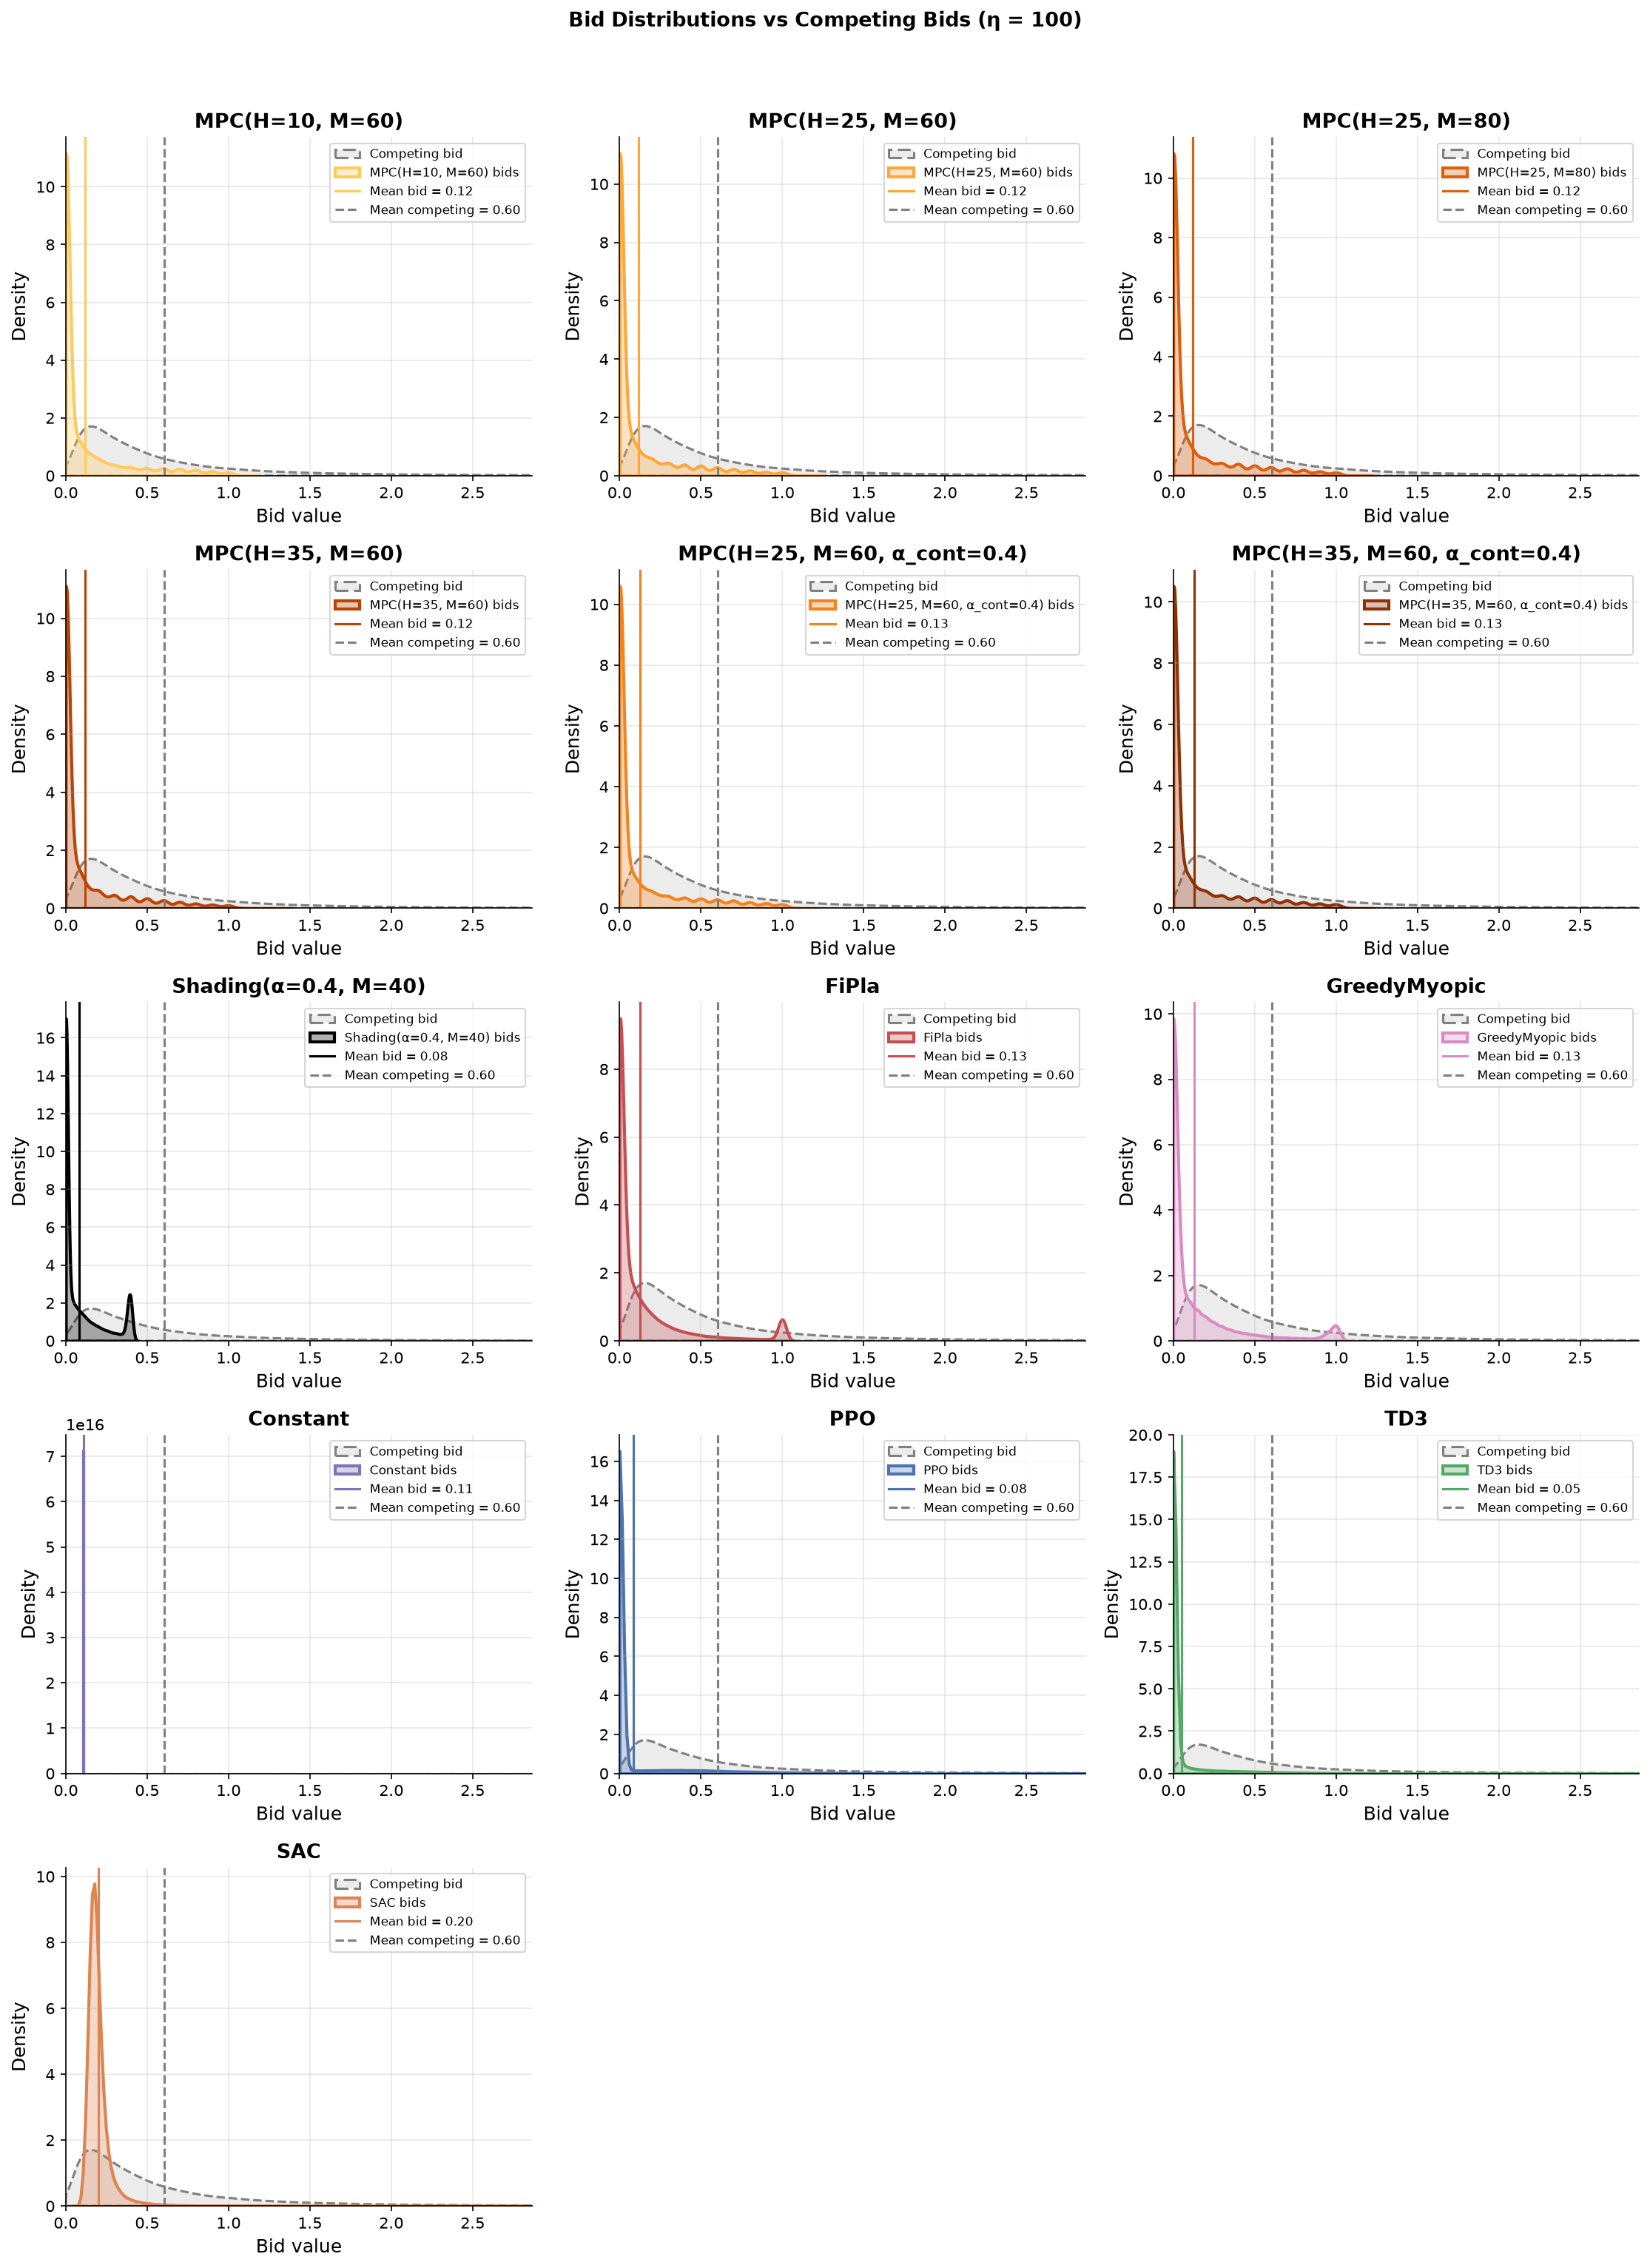

In [31]:
if df_eta100 is not None:
    _ = plots.plot_bid_distributions(df_eta100, filename="bid_distributions_eta100.pdf", title="Bid Distributions vs Competing Bids (η = 100)")
else:
    print("η = 100: results not available yet")

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:653: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:660: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/win_rate_eta50.pdf


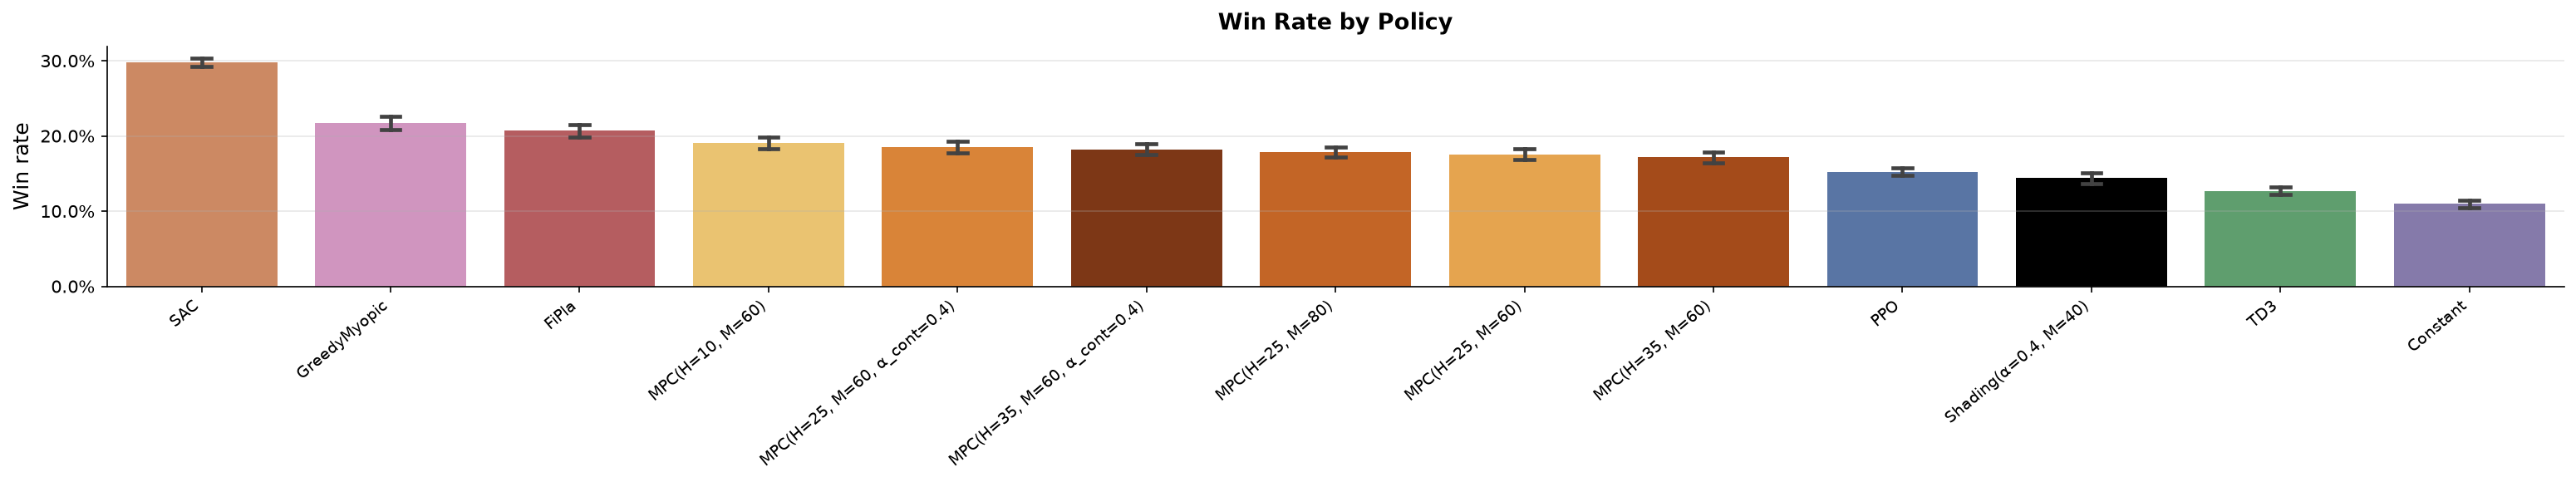

In [32]:
_ = plots.plot_win_rate(df_eta50, filename="win_rate_eta50.pdf")

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:653: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:660: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/win_rate_eta100.pdf


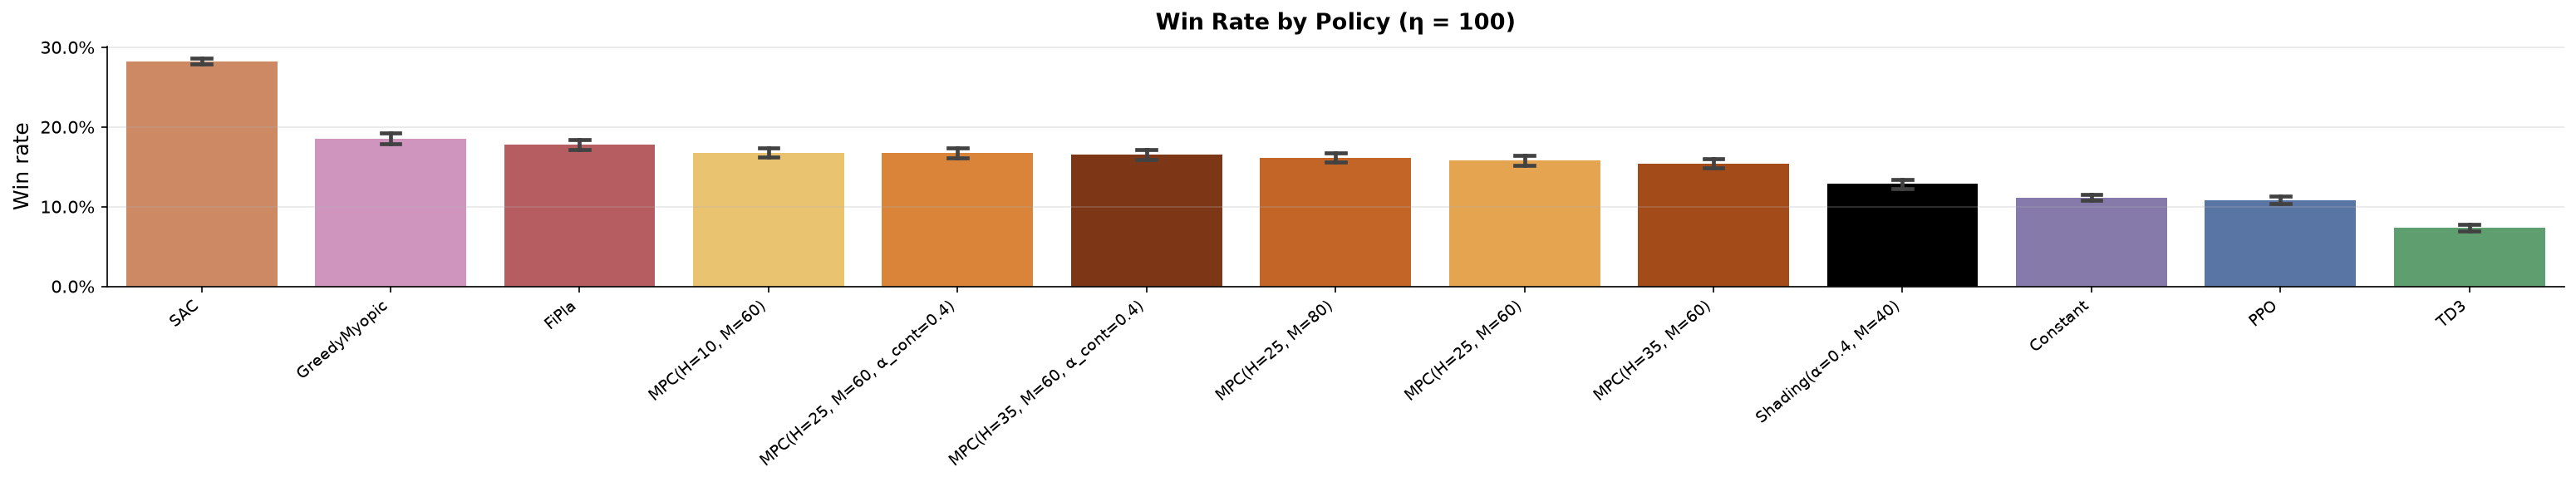

In [33]:
if df_eta100 is not None:
    _ = plots.plot_win_rate(df_eta100, filename="win_rate_eta100.pdf", title="Win Rate by Policy (η = 100)")
else:
    print("η = 100: results not available yet")

### MPC's optimal alphas

At each auction step, MPC-family policies select the shading multiplier α* that maximises the estimated planning return over a rolling horizon. The distribution below shows which α* values are preferred across all steps and seeds, a concentration near high α values indicates the policy tends to bid aggressively, while a spread across the candidate set suggests the optimal multiplier is context-dependent.

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:823: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/mpc_alpha_chosen_eta50.pdf


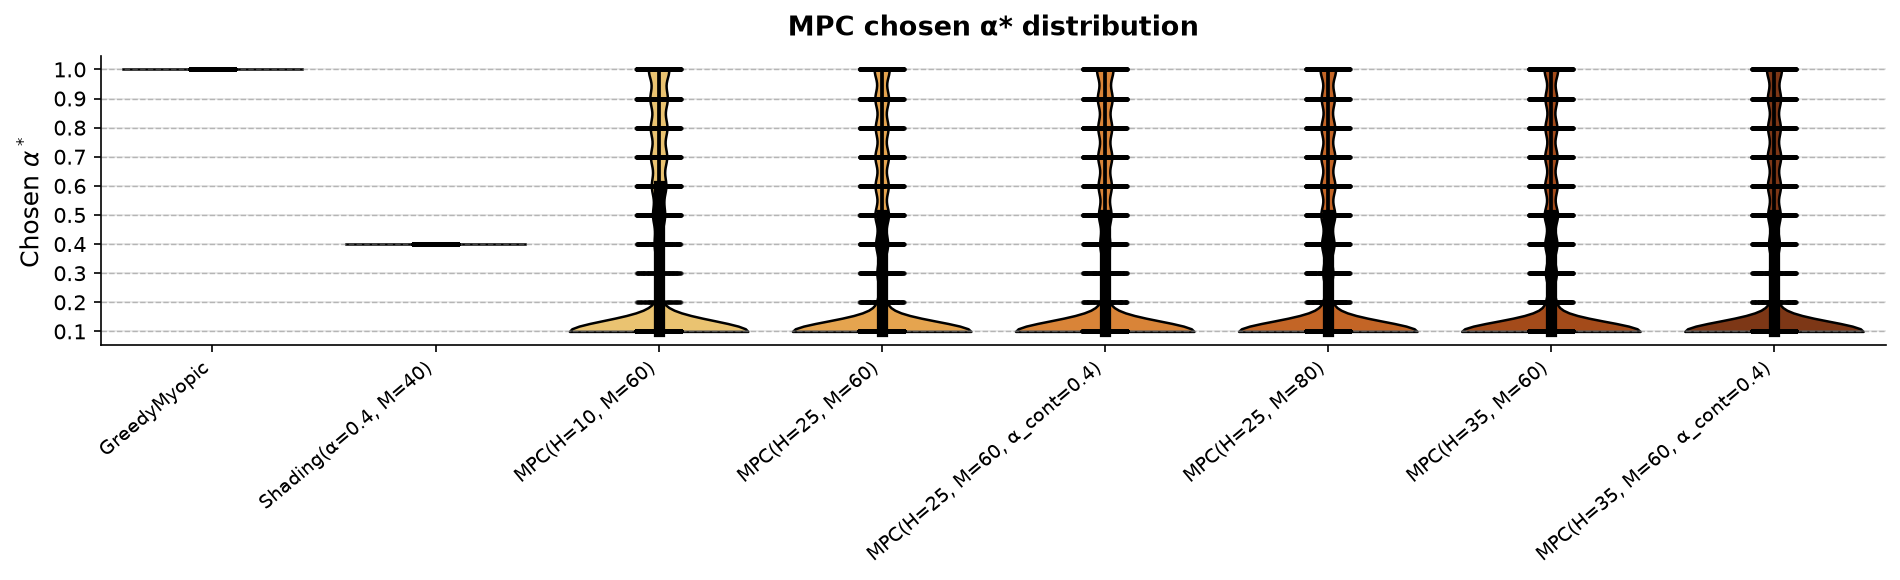

In [34]:
_ = plots.plot_mpc_alpha_chosen(df_eta50, filename="mpc_alpha_chosen_eta50.pdf")

/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:823: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",
/home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/mpc_alpha_chosen_eta100.pdf


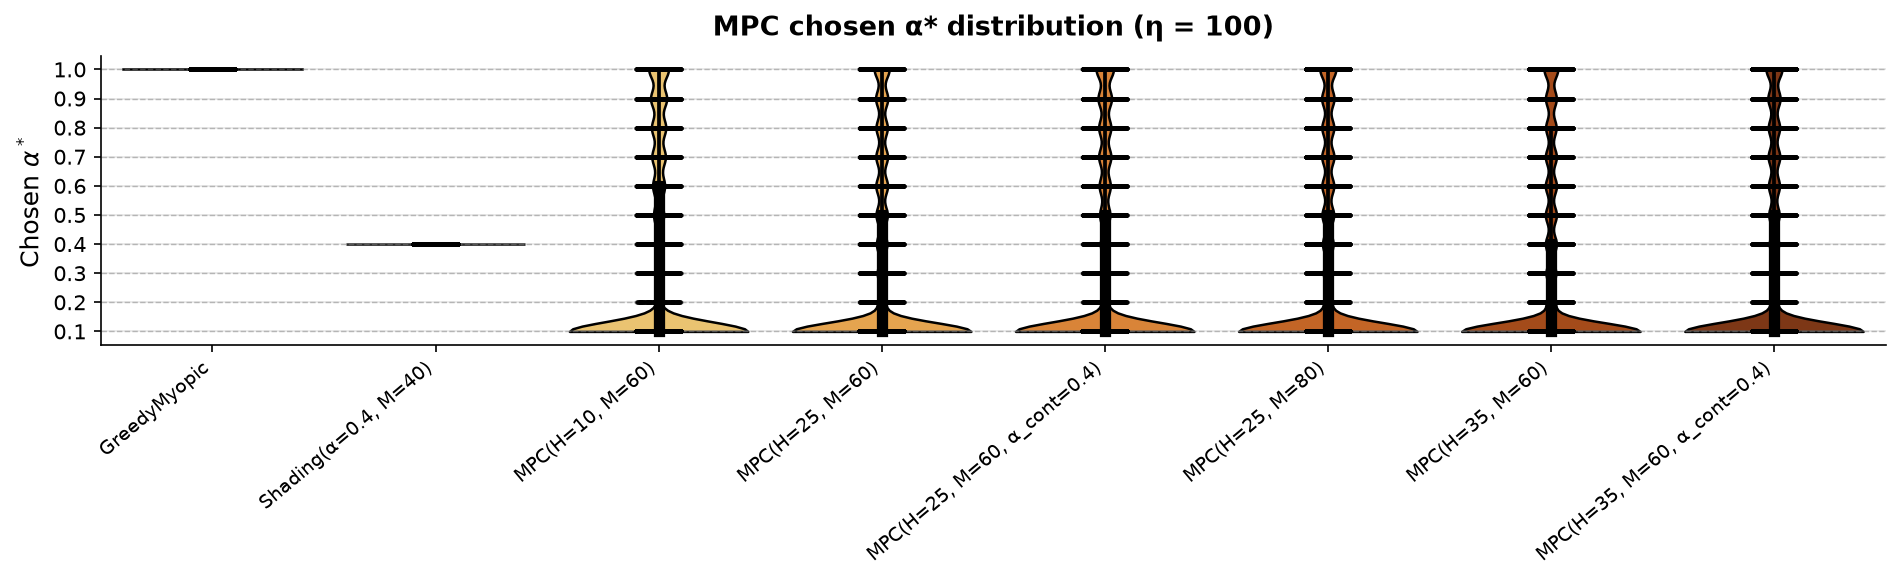

In [35]:
if df_eta100 is not None:
    _ = plots.plot_mpc_alpha_chosen(df_eta100, filename="mpc_alpha_chosen_eta100.pdf", title="MPC chosen α* distribution (η = 100)")
else:
    print("η = 100: results not available yet")

### MPC chosen α* over normalised campaign time

Because campaign horizons are exponentially distributed (different length per seed), time is normalised to [0, 1] for each run before averaging. The curves show how the preferred shading multiplier evolves from the start to the end of a campaign.

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/mpc_alpha_over_time_eta50.pdf


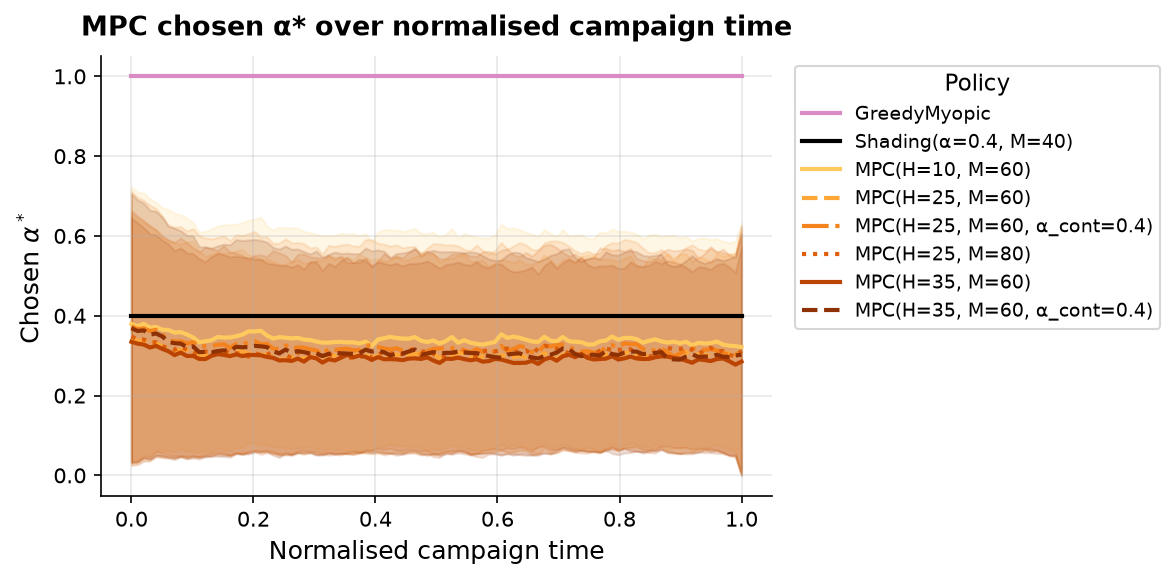

In [36]:
_ = plots.plot_alpha_over_normalized_time(df_eta50, filename="mpc_alpha_over_time_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/dynamicauc-project/dynamauction/benchmark/plots/mpc_alpha_over_time_eta100.pdf


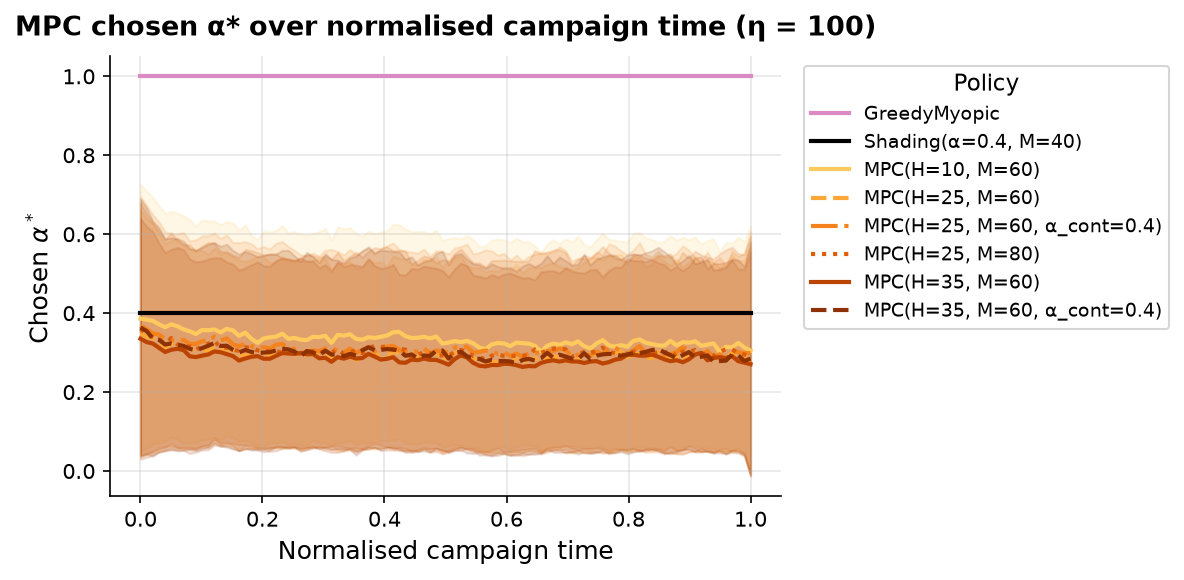

In [37]:
if df_eta100 is not None:
    _ = plots.plot_alpha_over_normalized_time(df_eta100, filename="mpc_alpha_over_time_eta100.pdf", title="MPC chosen α* over normalised campaign time (η = 100)")
else:
    print("η = 100: results not available yet")